<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">DATOS MASIVOS II · PRÁCTICA</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Calidad y preprocesamiento de la red de citas cit-HepPh</div><div style="opacity:.72;font-size:14px;margin-top:6px;">Perfilado de las aristas y de las fechas de envío a arXiv, enlace entre ambos archivos y limpieza del grafo para PageRank, HITS y PageRank sensible a tópico.</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

### Objetivo

Revisar la calidad de los dos archivos que forman la red de citas **cit-HepPh** antes de analizarla con PageRank, HITS
y PageRank sensible a tópico. Cada archivo se perfila por separado y después se cruzan: los identificadores de los
artículos son la llave que une las aristas con las fechas, así que cualquier error en ellos se propaga a todo lo demás.
La limpieza se aplica sobre una copia y el resultado se guarda en `data/processed/` para los notebooks 2 y 3.

### Los datos

Stanford Network Analysis Project (SNAP), [cit-HepPh](https://snap.stanford.edu/data/cit-HepPh.html). Es la red de citas
entre artículos de la categoría *High Energy Physics – Phenomenology* (`hep-ph`) de arXiv, publicada para la KDD Cup 2003
(Gehrke, Ginsparg y Kleinberg, 2003) y usada por Leskovec, Kleinberg y Faloutsos (2005). Si el artículo *i* cita al
artículo *j*, el grafo tiene la arista dirigida *i → j*. Las citas hacia artículos fuera del conjunto, o desde ellos, no
están en el grafo.

| Archivo | Contenido |
|---|---|
| `data/cit-HepPh.txt.gz` | Lista de aristas dirigidas: `FromNodeId`, `ToNodeId`. |
| `data/cit-HepPh-dates.txt.gz` | Fecha de envío a arXiv de cada artículo: `id`, `fecha`. |

Estadísticas que publica SNAP, para comparar: **34,546 nodos**, **421,578 aristas**, componente débilmente conexa mayor
de 34,401 nodos, fuertemente conexa mayor de 12,711 nodos, diámetro 12, periodo de enero de 1993 a abril de 2003.

### Contenido

1. **Los dos archivos: carga y formato.** Cabeceras, separador, número de campos y tipos.
2. **Identificadores.** Ceros a la izquierda perdidos en las aristas y artículos *cross-listed* en las fechas, incluidos
   los que aparecen disfrazados de IDs de 7 dígitos. Se normaliza la llave común.
3. **Unicidad.** Aristas duplicadas, 44 autocitas, 657 pares recíprocos e IDs repetidos en las fechas.
4. **Completitud y enlace de registros.** Cobertura de fechas (88.46 % de los nodos), su corte en marzo de 2002 y el mes
   del ID como respaldo.
5. **Consistencia temporal.** Citas al futuro y fechas fuera del periodo anunciado.
6. **Estructura del grafo.** Grados en escala log-log, nodos colgantes, WCC, SCC y ciclos.
7. **Atípicos de grado.** IQR y 3σ sobre el grado crudo y en $\log(1 + k)$, e Isolation Forest.
8. **Volumen por mes.** Artículos, citas hechas y citas recibidas, y la doble censura temporal.
9. **Resumen de calidad** y siguientes pasos de preprocesamiento, con su estado.
10. **Preprocesamiento y guardado** en `data/processed/`.

### Archivos

- `notebooks/01_eda_calidad_preprocesamiento.ipynb`: este notebook. Se ejecuta desde la carpeta `notebooks/`.
- `data/cit-HepPh.txt.gz` y `data/cit-HepPh-dates.txt.gz`: datos originales de SNAP (entrada).
- Salidas en `data/processed/`: `aristas_limpias.parquet`, `nodos_limpios.parquet` y `fechas_cross_listed.parquet`.
  No se suben al repositorio (`.gitignore`); se regeneran al ejecutar el notebook.

In [1]:
# Librerías, rutas, paleta y funciones auxiliares de estilo
import gzip
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 80)

RUTA_DATOS = Path("..") / "data"
RUTA_PROCESADOS = RUTA_DATOS / "processed"
ARCHIVO_ARISTAS = RUTA_DATOS / "cit-HepPh.txt.gz"
ARCHIVO_FECHAS = RUTA_DATOS / "cit-HepPh-dates.txt.gz"

# Paleta única del notebook: azul principal, rojo de acento y grises neutros
AZUL, ROJO = "#3D6FB0", "#B03D3D"
GRIS, GRIS_CLARO, TINTA = "#8C8C8C", "#EEF1F6", "#333333"
# Escala secuencial de un solo tono (azules) para conteos y densidades; vacío = blanco
CMAP_SEC = LinearSegmentedColormap.from_list("azules", plt.cm.Blues(np.linspace(0.22, 1, 256)))
CMAP_SEC.set_bad("white")

plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": "#999999", "axes.labelcolor": TINTA,
    "xtick.color": TINTA, "ytick.color": TINTA, "legend.frameon": False,
})


def estilo_ejes(ax, titulo=None, xlabel=None, ylabel=None, rejilla="y"):
    """
    Aplica el estilo común a unos ejes de matplotlib.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Ejes a formatear.
    titulo, xlabel, ylabel : str, opcional
        Título y etiquetas de los ejes (con unidades).
    rejilla : {"x", "y", "both", None}
        Eje sobre el que se dibuja una rejilla tenue.
    """
    if titulo:
        ax.set_title(titulo)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)


def pct(x, dec=2):
    """Formatea una proporción como porcentaje con espacio antes del símbolo."""
    return f"{100 * x:,.{dec}f} %"

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Los dos archivos: carga y formato</span></div>


Antes de cargar las tablas se revisa el archivo como texto: qué dicen las líneas de comentario (`#`), si todas las
líneas de datos tienen el mismo número de campos y si el separador es siempre el tabulador. Es la dimensión de
**validez** de la Unidad 2: un dato puede estar presente y aun así no cumplir el formato esperado.

Las dos tablas se leen con `dtype=str`. Los identificadores parecen números, pero son **códigos**: leerlos como enteros
borraría los ceros a la izquierda, que forman parte del identificador de arXiv (sección 2).

In [2]:
# Líneas de comentario y revisión de formato de los dos archivos, línea por línea
def leer_lineas(ruta):
    """
    Lee un archivo de texto comprimido con gzip y lo separa en líneas de comentario y de datos.

    Parámetros
    ----------
    ruta : pathlib.Path
        Ruta al archivo `.txt.gz`.

    Retorna
    -------
    tuple of (list of str, list of str)
        Líneas que empiezan con '#' y líneas de datos, sin el salto de línea final.
    """
    with gzip.open(ruta, "rt", encoding="utf-8") as fh:
        lineas = fh.read().splitlines()
    comentarios = [l for l in lineas if l.startswith("#")]
    datos = [l for l in lineas if not l.startswith("#")]
    return comentarios, datos


def revisar_formato(datos):
    """
    Resume el formato de las líneas de datos de un archivo separado por tabuladores.

    Parámetros
    ----------
    datos : list of str
        Líneas de datos (sin comentarios).

    Retorna
    -------
    pd.Series
        Conteos de líneas, campos por línea, líneas vacías, espacios sobrantes y separadores inesperados.
    """
    campos = pd.Series([len(l.split("\t")) for l in datos])
    return pd.Series({
        "Líneas de datos": f"{len(datos):,}",
        "Campos por línea (valores distintos)": ", ".join(map(str, sorted(campos.unique()))),
        "Líneas vacías": sum(l.strip() == "" for l in datos),
        "Líneas con espacios al inicio o al final": sum(l != l.strip() for l in datos),
        "Líneas con espacios internos": sum(" " in l.strip() for l in datos),
    })


formato = {}
for ruta in (ARCHIVO_ARISTAS, ARCHIVO_FECHAS):
    comentarios, datos = leer_lineas(ruta)
    print(f"{ruta.name}: {len(comentarios)} líneas de comentario")
    for linea in comentarios:
        print(f"    {linea}")
    formato[ruta.name] = revisar_formato(datos)
    formato[ruta.name]["Líneas de comentario"] = len(comentarios)

display(pd.DataFrame(formato).rename_axis("Revisión"))

cit-HepPh.txt.gz: 4 líneas de comentario
    # Directed graph (each unordered pair of nodes is saved once): Cit-HepPh.txt 
    # Paper citation network of Arxiv High Energy Physics category
    # Nodes: 34546 Edges: 421578
    # FromNodeId	ToNodeId


cit-HepPh-dates.txt.gz: 1 líneas de comentario
    # cross-listed papers have ids 11<true_id>


,cit-HepPh.txt.gz,cit-HepPh-dates.txt.gz
Revisión,,
Líneas de datos,"421,578","38,557"
Campos por línea (valores distintos),2,2
Líneas vacías,0,0
Líneas con espacios al inicio o al final,0,0
Líneas con espacios internos,0,0
Líneas de comentario,4,1


In [3]:
# Carga de las dos tablas como texto y vista general
aristas_raw = pd.read_csv(ARCHIVO_ARISTAS, sep="\t", comment="#", header=None,
                          names=["origen", "destino"], dtype=str)
fechas_raw = pd.read_csv(ARCHIVO_FECHAS, sep="\t", comment="#", header=None,
                         names=["id", "fecha"], dtype=str)

for nombre, df in [("aristas_raw", aristas_raw), ("fechas_raw", fechas_raw)]:
    print(f"{nombre}: {df.shape[0]:,} filas × {df.shape[1]} columnas")
    display(df.head())

# Tipos de valor: los IDs deben ser solo dígitos y las fechas, AAAA-MM-DD válidas
fecha_dt = pd.to_datetime(fechas_raw["fecha"], format="%Y-%m-%d", errors="coerce")
revision = pd.Series({
    "Faltantes en aristas_raw": int(aristas_raw.isna().sum().sum()),
    "Faltantes en fechas_raw": int(fechas_raw.isna().sum().sum()),
    "IDs de aristas que no son solo dígitos": int((~aristas_raw.stack().str.fullmatch(r"\d+")).sum()),
    "IDs de fechas que no son solo dígitos": int((~fechas_raw["id"].str.fullmatch(r"\d+")).sum()),
    "Fechas que no se pueden leer como AAAA-MM-DD": int(fecha_dt.isna().sum()),
    "Fecha mínima": f"{fecha_dt.min():%d/%m/%Y}",
    "Fecha máxima": f"{fecha_dt.max():%d/%m/%Y}",
}, name="Valor").rename_axis("Revisión").to_frame()
display(revision)

n_nodos_aristas = pd.unique(aristas_raw.to_numpy().ravel()).size
print(f"Nodos distintos en las aristas: {n_nodos_aristas:,} (SNAP: 34,546) | aristas: {len(aristas_raw):,} (SNAP: 421,578)")

aristas_raw: 421,578 filas × 2 columnas


,origen,destino
0,9907233,9301253
1,9907233,9504304
2,9907233,9505235
3,9907233,9506257
4,9907233,9606402


fechas_raw: 38,557 filas × 2 columnas


,id,fecha
0,9203201,1992-02-24
1,9203202,1992-03-08
2,9203203,1992-03-03
3,9203204,1992-03-09
4,9203205,1992-03-09


,Valor
Revisión,
Faltantes en aristas_raw,0
Faltantes en fechas_raw,0
IDs de aristas que no son solo dígitos,0
IDs de fechas que no son solo dígitos,0
Fechas que no se pueden leer como AAAA-MM-DD,0
Fecha mínima,11/02/1992
Fecha máxima,12/03/2002


Nodos distintos en las aristas: 34,546 (SNAP: 34,546) | aristas: 421,578 (SNAP: 421,578)


**Observaciones: formato de los archivos**

- **Cabeceras.** El archivo de aristas declara **34,546 nodos y 421,578 aristas** y aclara que *"each unordered pair of
  nodes is saved once"*: si eso se cumple, no puede haber pares recíprocos *i → j*, *j → i* (se comprueba en la sección
  de estructura del grafo). El archivo de fechas solo trae un aviso: los artículos *cross-listed* tienen el ID
  `11<id verdadero>` (sección 2).
- **Formato válido en los dos archivos.** Las **421,578** y **38,557** líneas de datos tienen exactamente **2 campos**
  separados por tabulador, sin líneas vacías ni espacios sobrantes. No hay faltantes, todos los IDs son solo dígitos y
  todas las fechas se leen como AAAA-MM-DD.
- **Los conteos coinciden con SNAP:** **34,546** nodos distintos y **421,578** aristas.
- **Primeras alertas para las secciones siguientes.**
  - El archivo de fechas tiene **38,557** filas, más que nodos el grafo.
  - Sus fechas van del **11/02/1992** al **12/03/2002**, no de enero de 1993 a abril de 2003 como dice SNAP.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · IDENTIFICADORES</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Identificadores</span></div>


Los artículos de arXiv anteriores a 2007 tienen identificadores del tipo `hep-ph/AAMMNNN`: dos dígitos de año, dos de
mes y tres de número consecutivo dentro del mes. Por ejemplo, `hep-ph/0001001` es el primer artículo de enero de 2000.
En los archivos solo aparece la parte numérica, así que **un identificador válido tiene 7 dígitos** y los artículos de
2000 en adelante empiezan con `0`.

Esta sección corresponde a la etapa de **limpieza y estandarización** del flujo de enlace de registros (Unidad 4):
antes de comparar las llaves de dos fuentes hay que llevarlas a la misma forma. Se revisan tres cosas:

1. **Longitud y primeros dígitos** de los IDs en cada columna.
2. **Validez** de los IDs de las aristas como números de arXiv (mes entre 01 y 12, año dentro del periodo).
3. **Coherencia** entre el `AAMM` del ID y la fecha del archivo de fechas, que permite detectar IDs mal formados.

In [4]:
# Longitud y primeros dígitos de los IDs en cada columna
def perfil_longitud(ids, fuente):
    """
    Cuenta los IDs por número de dígitos y marca los que empiezan con '0' o con '11'.

    Parámetros
    ----------
    ids : pd.Series
        IDs como texto.
    fuente : str
        Nombre de la columna de origen, para la tabla.

    Retorna
    -------
    pd.DataFrame
        Una fila por longitud con conteo, porcentaje, IDs que empiezan con '0' y con '11', y ejemplos.
    """
    filas = []
    for largo, grupo in ids.groupby(ids.str.len()):
        filas.append({
            "fuente": fuente, "dígitos": largo, "filas": len(grupo), "%": pct(len(grupo) / len(ids)),
            "empiezan con 0": int(grupo.str.startswith("0").sum()),
            "empiezan con 11": int(grupo.str.startswith("11").sum()),
            "ejemplos": ", ".join(grupo.drop_duplicates().head(3)),
        })
    return pd.DataFrame(filas)


display(pd.concat([perfil_longitud(aristas_raw["origen"], "aristas: origen"),
                   perfil_longitud(aristas_raw["destino"], "aristas: destino"),
                   perfil_longitud(fechas_raw["id"], "fechas: id")], ignore_index=True)
        .set_index(["fuente", "dígitos"]))
for col in ["origen", "destino"]:
    print(f"Aristas con {col} de menos de 7 dígitos: {pct((aristas_raw[col].str.len() < 7).mean())}")

filas        %  empiezan con 0  empiezan con 11                         ejemplos
fuente           dígitos                                                                                   
aristas: origen  4         45750  10.85 %               0             1359                 2171, 3033, 3183
                 5         16282   3.86 %               0             6059              12308, 12029, 11337
                 6        158061  37.49 %               0            20261           112133, 104110, 104062
                 7        201485  47.79 %               0                0        9907233, 9704296, 9606402
aristas: destino 4         25780   6.12 %               0              794                 2171, 1113, 1297
                 5          7943   1.88 %               0             2768              12308, 11238, 11358
                 6         41199   9.77 %               0             5676           104062, 104110, 112008
                 7        346656  82.23 %               0                0        9301253, 9504304, 9505235
fechas: id       7         32951  85.46 %            9827              300        9203201, 9203202, 9203203
                 8          1287   3.34 %               0             1287     11101013, 11101014, 11101016
                 9          4319  11.20 %               0             4319  119203001, 119203060, 119204017

Aristas con origen de menos de 7 dígitos: 52.21 %
Aristas con destino de menos de 7 dígitos: 17.77 %


In [5]:
# Validez de los IDs de las aristas como números de arXiv AAMMNNN, después de rellenar con ceros a 7 dígitos
def partes_arxiv(id7):
    """
    Separa un ID de arXiv de 7 dígitos en año (4 dígitos), mes y número consecutivo.

    Parámetros
    ----------
    id7 : pd.Series
        IDs como texto de exactamente 7 dígitos.

    Retorna
    -------
    pd.DataFrame
        Columnas `anio`, `mes` y `numero` (enteros). Los años 91–99 se leen como 19xx y el resto como 20xx.
    """
    aa = id7.str[:2].astype(int)
    return pd.DataFrame({"anio": np.where(aa >= 91, 1900 + aa, 2000 + aa),
                         "mes": id7.str[2:4].astype(int),
                         "numero": id7.str[4:].astype(int)}, index=id7.index)


nodos_raw = pd.Series(pd.unique(aristas_raw.to_numpy().ravel()), name="id")
partes = partes_arxiv(nodos_raw.str.zfill(7))
print(f"Nodos de las aristas: {len(nodos_raw):,}")
print(f"Mes fuera de 01–12: {(~partes['mes'].between(1, 12)).sum():,} | número consecutivo 000: {(partes['numero'] == 0).sum():,}")
print(f"Rango del AAMM: {partes['anio'].min()}-{partes.loc[partes['anio'] == partes['anio'].min(), 'mes'].min():02d} a "
      f"{partes['anio'].max()}-{partes.loc[partes['anio'] == partes['anio'].max(), 'mes'].max():02d}")
print(f"Rellenar con ceros no crea colisiones: {nodos_raw.str.zfill(7).nunique():,} IDs distintos antes y después")
display(partes["anio"].value_counts().sort_index().rename("nodos").rename_axis("año del ID").to_frame().T)

Nodos de las aristas: 34,546
Mes fuera de 01–12: 0 | número consecutivo 000: 0
Rango del AAMM: 1992-03 a 2003-02
Rellenar con ceros no crea colisiones: 34,546 IDs distintos antes y después


año del ID,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003
nodos,582,1533,2308,2853,3202,3535,3723,4003,4025,4113,4137,532


El archivo de fechas tiene IDs de 7, 8 y 9 dígitos, y su cabecera avisa que los artículos *cross-listed* (enviados a
otra categoría y listados también en `hep-ph`) llevan el ID `11<id verdadero>`. Para comprobarlo se compara el `AAMM`
de cada ID con el año y mes de su fecha de envío, de dos formas:

- **ID tal cual**, rellenado con ceros a 7 dígitos.
- **ID sin el prefijo `11`**: se quitan los ceros a la izquierda, se quita el `11` inicial y se rellena con ceros a 7 dígitos.

Un ID de arXiv se asigna cuando se anuncia el artículo, así que su `AAMM` debería coincidir con el mes de la fecha de
envío **o con el siguiente**: un artículo enviado el 28 de septiembre puede recibir un número de octubre. Por eso se acepta
una diferencia de 0 o 1 mes. Si un ID es incoherente tal cual pero coherente sin el `11`, es un *cross-listed* mal formado.

In [6]:
# Coherencia entre el AAMM del ID y el mes de la fecha, por tipo de ID del archivo de fechas
def indice_mes(id7):
    """
    Convierte el AAMM de un ID de 7 dígitos en un índice de mes (año·12 + mes − 1).

    Parámetros
    ----------
    id7 : pd.Series
        IDs como texto de 7 dígitos (puede tener nulos).

    Retorna
    -------
    pd.Series
        Índice de mes como float; nulo si el ID es nulo o su mes no está entre 01 y 12.
    """
    aa = pd.to_numeric(id7.str[:2], errors="coerce")
    mm = pd.to_numeric(id7.str[2:4], errors="coerce")
    anio = np.where(aa >= 91, 1900 + aa, 2000 + aa)
    return pd.Series(np.where(mm.between(1, 12), anio * 12 + mm - 1, np.nan), index=id7.index)


def aamm_coincide(id7, fecha, tolerancia=1):
    """
    Indica si el AAMM de un ID cae entre el mes de la fecha de envío y `tolerancia` meses después.

    Parámetros
    ----------
    id7 : pd.Series
        IDs como texto de 7 dígitos (puede tener nulos).
    fecha : pd.Series
        Fechas como texto AAAA-MM-DD, con el mismo índice.
    tolerancia : int
        Meses de desfase permitidos entre el envío y el número asignado.

    Retorna
    -------
    pd.Series
        Booleana; los IDs nulos o con mes inválido dan False.
    """
    f = pd.to_datetime(fecha, format="%Y-%m-%d")
    return (indice_mes(id7) - (f.dt.year * 12 + f.dt.month - 1)).between(0, tolerancia)


def quitar_prefijo_11(ids):
    """
    Quita el prefijo '11' de los IDs que lo tienen después de eliminar los ceros a la izquierda.

    Parámetros
    ----------
    ids : pd.Series
        IDs como texto.

    Retorna
    -------
    pd.Series
        ID verdadero rellenado con ceros a 7 dígitos, o nulo si el ID no empieza con '11'.
    """
    sin_ceros = ids.str.lstrip("0")
    return sin_ceros.where(sin_ceros.str.startswith("11")).str[2:].str.zfill(7)


def tipo_id_fechas(ids):
    """
    Clasifica los IDs del archivo de fechas por longitud y primeros dígitos.

    Parámetros
    ----------
    ids : pd.Series
        IDs como texto.

    Retorna
    -------
    pd.Series
        Etiqueta del grupo de cada ID.
    """
    largo = ids.str.len()
    return pd.Series(np.select(
        [largo == 9, largo == 8, ids.str.startswith("011"), ids.str.startswith("111")],
        ["9 dígitos (11 + 7)", "8 dígitos (11 + 6)", "7 dígitos, empieza con 011", "7 dígitos, empieza con 111"],
        default="7 dígitos, resto"), index=ids.index)


coh = fechas_raw.assign(
    tipo=tipo_id_fechas(fechas_raw["id"]),
    coincide_tal_cual=aamm_coincide(fechas_raw["id"].str.zfill(7), fechas_raw["fecha"]),
    coincide_sin_11=aamm_coincide(quitar_prefijo_11(fechas_raw["id"]), fechas_raw["fecha"]),
)
orden_tipos = ["7 dígitos, resto", "7 dígitos, empieza con 011", "7 dígitos, empieza con 111",
               "8 dígitos (11 + 6)", "9 dígitos (11 + 7)"]
tabla_coh = (coh.groupby("tipo")
             .agg(filas=("id", "size"), ids_distintos=("id", "nunique"),
                  coincide_tal_cual=("coincide_tal_cual", "sum"), coincide_sin_11=("coincide_sin_11", "sum"),
                  solo_sin_11=("coincide_sin_11", lambda s: int((s & ~coh.loc[s.index, "coincide_tal_cual"]).sum())))
             .reindex(orden_tipos).astype(int))
tabla_coh.loc["Total"] = tabla_coh.sum()
tabla_coh["% tal cual"] = (tabla_coh["coincide_tal_cual"] / tabla_coh["filas"]).map(pct)
tabla_coh["% sin 11"] = (tabla_coh["coincide_sin_11"] / tabla_coh["filas"]).map(pct)
display(tabla_coh)
print(f"IDs repetidos en el archivo de fechas (texto exacto): {fechas_raw['id'].duplicated().sum():,} filas")
estricto = aamm_coincide(fechas_raw["id"].str.zfill(7), fechas_raw["fecha"], tolerancia=0)
print(f"'7 dígitos, resto' coherentes en el mismo mes (sin tolerancia): "
      f"{pct(estricto[coh['tipo'] == '7 dígitos, resto'].mean())}")

,filas,ids_distintos,coincide_tal_cual,coincide_sin_11,solo_sin_11,% tal cual,% sin 11
tipo,,,,,,,
"7 dígitos, resto",30621,30621,30539,0,0,99.73 %,0.00 %
"7 dígitos, empieza con 011",2030,1801,1253,777,777,61.72 %,38.28 %
"7 dígitos, empieza con 111",300,261,0,300,300,0.00 %,100.00 %
8 dígitos (11 + 6),1287,1131,0,1287,1287,0.00 %,100.00 %
9 dígitos (11 + 7),4319,3807,0,4306,4306,0.00 %,99.70 %
Total,38557,37621,31792,6670,6670,82.45 %,17.30 %


IDs repetidos en el archivo de fechas (texto exacto): 936 filas
'7 dígitos, resto' coherentes en el mismo mes (sin tolerancia): 99.24 %


In [7]:
# Candidatos a cross-listed y colisiones con los IDs propios de hep-ph
candidato_cross = (coh["tipo"].isin(["8 dígitos (11 + 6)", "9 dígitos (11 + 7)", "7 dígitos, empieza con 111"])
                   | (coh["coincide_sin_11"] & ~coh["coincide_tal_cual"]))
propios = coh.loc[~candidato_cross, ["id", "fecha"]]
cruzados = coh.loc[candidato_cross, ["id", "fecha"]].assign(id_verdadero=lambda d: quitar_prefijo_11(d["id"]))
colisiones = cruzados.merge(propios, left_on="id_verdadero", right_on="id", suffixes=("_cross", "_propio"))
desfase = (pd.to_datetime(colisiones["fecha_cross"]) - pd.to_datetime(colisiones["fecha_propio"])).dt.days
nodos7 = set(nodos_raw.str.zfill(7))

print(f"Candidatos a cross-listed: {len(cruzados):,} filas ({cruzados['id'].nunique():,} IDs distintos) | "
      f"filas propias: {len(propios):,} ({propios['id'].nunique():,} IDs distintos)")
print(f"IDs propios repetidos: {propios['id'].duplicated().sum():,}")
print(f"Cross-listed cuyo ID verdadero también es un ID propio: {colisiones['id_cross'].nunique():,} IDs "
      f"| misma fecha en {pct((desfase == 0).mean())} de los {len(colisiones):,} pares "
      f"| desfase (cross − propio) mediano: {desfase.median():.0f} días, rango [{desfase.min()}, {desfase.max()}]")
solo_cross = sorted((set(cruzados["id_verdadero"]) & nodos7) - set(propios["id"]))
print(f"Nodos del grafo que solo tendrían fecha a través de un cross-listed: {len(solo_cross)} {solo_cross}")

print("\nEjemplos de IDs mal formados y de colisiones:")
ejemplos = ["0111002", "0115003", "1110002", "0110001", "119406208", "9406208"]
display(coh[coh["id"].isin(ejemplos)].assign(id_sin_11=lambda d: quitar_prefijo_11(d["id"]),
                                            candidato_cross=candidato_cross)
        .sort_values(["id", "fecha"])[["id", "fecha", "tipo", "id_sin_11", "coincide_tal_cual",
                                       "coincide_sin_11", "candidato_cross"]])

Candidatos a cross-listed: 6,683 filas (5,874 IDs distintos) | filas propias: 31,874 (31,874 IDs distintos)
IDs propios repetidos: 0
Cross-listed cuyo ID verdadero también es un ID propio: 2,254 IDs | misma fecha en 6.77 % de los 2,557 pares | desfase (cross − propio) mediano: 6 días, rango [-15, 34]
Nodos del grafo que solo tendrían fecha a través de un cross-listed: 3 ['0203137', '0203149', '0203164']

Ejemplos de IDs mal formados y de colisiones:


,id,fecha,tipo,id_sin_11,coincide_tal_cual,coincide_sin_11,candidato_cross
36111,0110001,2001-09-28,"7 dígitos, empieza con 011",0000001,True,False,False
27494,0111002,2000-01-01,"7 dígitos, empieza con 011",0001002,False,True,True
27502,0111002,2000-01-01,"7 dígitos, empieza con 011",0001002,False,True,True
27509,0111002,2000-01-03,"7 dígitos, empieza con 011",0001002,False,True,True
36654,0111002,2001-10-31,"7 dígitos, empieza con 011",0001002,True,False,False
29030,0115003,2000-04-29,"7 dígitos, empieza con 011",0005003,False,True,True
31339,1110002,2000-09-30,"7 dígitos, empieza con 111",0010002,False,True,True
4183,119406208,1994-07-01,9 dígitos (11 + 7),9406208,False,False,True
3936,9406208,1994-06-01,"7 dígitos, resto",NaN,True,False,False


**Observaciones: identificadores**

- **Las aristas perdieron los ceros a la izquierda.** Ningún ID de las aristas empieza con `0` y hay IDs de 4, 5 y 6
  dígitos: son artículos de 2000 en adelante guardados como enteros (por ejemplo, `2171` es `0002171`). Son el
  **52.21 %** de los orígenes y el **17.77 %** de los destinos. La asimetría es esperable: las citas apuntan hacia
  atrás en el tiempo, así que los citados son en su mayoría de los años noventa (**82.23 %** de destinos de 7 dígitos).
- **Rellenar con ceros a 7 dígitos los repara sin ambigüedad.** Ningún ID queda con un mes fuera de 01–12 ni con número
  000, siguen siendo **34,546** IDs distintos y el `AAMM` va de **1992-03 a 2003-02**. Los IDs de las aristas que
  empiezan con `11` no son *cross-listed*: son artículos de 2001 sin el cero (`112133` = `0112133`, diciembre de 2001).
- **El archivo de fechas sí conserva los ceros** (**9,827** IDs empiezan con `0`), así que la llave común es el ID de
  **7 dígitos como texto**.
- **Los IDs de 8 y 9 dígitos son *cross-listed*, como avisa la cabecera.** Todos empiezan con `11`; ninguno es coherente
  con su fecha tal cual y, sin el `11`, lo son el **100.00 %** (8 dígitos) y el **99.70 %** (9 dígitos). Los de 8
  dígitos muestran cómo se generaron: el `11` se pegó al ID **ya sin ceros** (`11101013` = `11` + `101013`, es decir,
  `0101013`).
- **Hallazgo: hay *cross-listed* disfrazados de IDs de 7 dígitos.** El mismo error produce IDs de 7 dígitos cuando el ID
  verdadero tenía 4 o 5 cifras significativas:
  - los **300** que empiezan con `111` son todos *cross-listed* (un año "11" es imposible y el **100.00 %** es coherente sin el `11`);
  - de los **2,030** que empiezan con `011`, **777** son *cross-listed* y **1,253** son artículos genuinos de octubre a
    diciembre de 2001. Por ejemplo, `0111002` aparece 4 veces: 3 con fechas de enero de 2000 (el *cross-listed*
    `0001002`) y 1 del 31/10/2001 (el `hep-ph/0111002` real). `0115003` tiene un mes 15, que no existe.
- **Tolerancia de un mes.** Entre los IDs de 7 dígitos sin prefijo, el **99.24 %** coincide en el mismo mes y el
  **99.73 %** con un mes de tolerancia; con ella, ningún ID `011…` queda ambiguo.
- **Con esta regla** hay **6,683** filas *cross-listed* (**5,874** IDs) y **31,874** filas propias **sin ningún ID
  repetido**. Las **936** filas repetidas del archivo de fechas se explican todas por los *cross-listed*.
- **Colisiones.** **2,254** IDs *cross-listed* tienen un ID verdadero que también es un ID propio de `hep-ph`, y solo el
  **6.77 %** de esos pares tiene la misma fecha (desfase mediano de **6 días**, rango de −15 a 34). El prefijo no dice de
  qué categoría viene el artículo, así que no se puede saber si es el mismo artículo o uno distinto con el mismo número.
  Si se quitara el `11` sin más, un mismo nodo quedaría con dos fechas.
- **Los *cross-listed* casi no aportan al grafo:** solo **3** nodos (`0203137`, `0203149` y `0203164`) tendrían fecha
  únicamente a través de un *cross-listed*.

**Decisión: normalización de los IDs**

- **Llave común:** el ID de arXiv de **7 dígitos como texto**. Los IDs de las aristas se rellenan con ceros a la
  izquierda (`zfill(7)`).
- **Fechas de los nodos:** se usan **solo las filas propias** de `hep-ph`. Los *cross-listed* (explícitos y disfrazados)
  se separan en una tabla aparte que se conserva para documentarlos, pero no se cruzan con el grafo. Es la regla de
  Unidad 4 de no enlazar registros cuya equivalencia no se puede establecer: el ID verdadero de un *cross-listed*
  coincide en número con un artículo de `hep-ph`, pero en el **93.23 %** de los pares la fecha no coincide.
- **Los 3 nodos que solo tendrían fecha por un *cross-listed*** quedan sin fecha. Antes se revisan para confirmar que no
  se pierde nada importante.

In [8]:
# Revisión de los 3 nodos que solo tendrían fecha a través de un cross-listed
aristas7 = aristas_raw.apply(lambda s: s.str.zfill(7))
grado_sal = aristas7["origen"].value_counts()
grado_ent = aristas7["destino"].value_counts()
ultima_propia = propios["fecha"].max()
mes_0203 = propios[propios["id"].str.startswith("0203")]

revision_3 = pd.DataFrame({
    "grado de salida": [int(grado_sal.get(n, 0)) for n in solo_cross],
    "grado de entrada": [int(grado_ent.get(n, 0)) for n in solo_cross],
    "fecha del cross-listed": [", ".join(cruzados.loc[cruzados["id_verdadero"] == n, "fecha"]) for n in solo_cross],
    "ID cross-listed": [", ".join(cruzados.loc[cruzados["id_verdadero"] == n, "id"]) for n in solo_cross],
}, index=pd.Index(solo_cross, name="nodo"))
display(revision_3)
print(f"Última fecha propia del archivo: {ultima_propia} | IDs propios de marzo de 2002 (0203…): {len(mes_0203):,}, "
      f"del {mes_0203['id'].min()} al {mes_0203['id'].max()}")
print(f"Nodos del grafo con ID 0203…: {sum(n.startswith('0203') for n in nodos7):,}")

,grado de salida,grado de entrada,fecha del cross-listed,ID cross-listed
nodo,,,,
0203137,39,24,2002-03-08,11203137
0203149,8,8,2002-03-10,11203149
0203164,11,1,2002-03-11,11203164


Última fecha propia del archivo: 2002-03-12 | IDs propios de marzo de 2002 (0203…): 109, del 0203001 al 0203109
Nodos del grafo con ID 0203…: 268


In [9]:
# Tablas normalizadas: aristas con IDs de 7 dígitos, fechas propias y cross-listed por separado
aristas = aristas7.copy()
fechas = propios.assign(fecha=pd.to_datetime(propios["fecha"], format="%Y-%m-%d")).reset_index(drop=True)
fechas_cross = (cruzados.assign(fecha=pd.to_datetime(cruzados["fecha"], format="%Y-%m-%d"),
                                tipo=coh.loc[cruzados.index, "tipo"])
                .reset_index(drop=True))

resumen_norm = pd.Series({
    "Aristas": f"{len(aristas):,}",
    "Nodos distintos en las aristas": f"{pd.unique(aristas.to_numpy().ravel()).size:,}",
    "IDs de aristas con 7 dígitos": pct(aristas.stack().str.len().eq(7).mean()),
    "Filas de fechas propias (IDs distintos)": f"{len(fechas):,} ({fechas['id'].nunique():,})",
    "Filas de fechas cross-listed (IDs distintos)": f"{len(fechas_cross):,} ({fechas_cross['id'].nunique():,})",
    "Filas del archivo original": f"{len(fechas_raw):,} = {len(fechas):,} + {len(fechas_cross):,}",
}, name="Valor").rename_axis("Tabla normalizada").to_frame()
display(resumen_norm)
display(fechas_cross["tipo"].value_counts().rename("filas").to_frame())

,Valor
Tabla normalizada,
Aristas,"421,578"
Nodos distintos en las aristas,"34,546"
IDs de aristas con 7 dígitos,100.00 %
Filas de fechas propias (IDs distintos),"31,874 (31,874)"
Filas de fechas cross-listed (IDs distintos),"6,683 (5,874)"
Filas del archivo original,"38,557 = 31,874 + 6,683"


,filas
tipo,
9 dígitos (11 + 7),4319
8 dígitos (11 + 6),1287
"7 dígitos, empieza con 011",777
"7 dígitos, empieza con 111",300


**Observaciones: los 3 nodos y las tablas normalizadas**

- **Los 3 nodos son de marzo de 2002**, justo donde termina el archivo de fechas: la última fecha propia es el
  **2002-03-12** y los IDs propios de ese mes llegan solo hasta `0203109`, mientras que el grafo tiene **268** nodos
  `0203…`. Les falta la fecha porque el archivo de fechas se corta, no por los *cross-listed*.
- **Sus fechas *cross-listed* (del 8 al 11 de marzo) no encajan con la numeración de `hep-ph`.** `0203137` es posterior a
  `0203109`, que ya tiene fecha del 12 de marzo, y aun así su *cross-listed* dice 8 de marzo. Lo más probable es que sea
  otro artículo con el mismo número en otra categoría, lo que respalda no usarlos.
- **Peso en el grafo.** El más conectado, `0203137`, tiene **39** citas de salida y **24** de entrada. Quedarse sin
  fecha solo los excluye de los análisis temporales; siguen en el grafo para PageRank y HITS.
- **Tablas normalizadas.**
  - `aristas` conserva las **421,578** aristas y los **34,546** nodos, con el **100.00 %** de los IDs de 7 dígitos.
  - `fechas` tiene **31,874** filas, una por ID.
  - `fechas_cross` guarda las **6,683** filas restantes: **4,319** de 9 dígitos, **1,287** de 8, **777** `011…` y
    **300** `111…`.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CALIDAD</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Unicidad</span></div>


La **unicidad** (Unidad 2) pide que cada entidad aparezca una sola vez. En una lista de aristas la entidad es la cita,
así que se buscan **duplicados exactos** (Unidad 3, parte 1) del par (origen, destino). Además se revisan dos casos
propios de una red de citas:

- **Auto-citas** (*i → i*): un artículo no puede citarse a sí mismo en su propia bibliografía. En PageRank son un lazo
  que devuelve al mismo nodo parte de su puntaje en cada iteración.
- **Pares recíprocos** (*i → j* y *j → i*): no son duplicados exactos, pero la cabecera dice que cada par no ordenado
  se guarda una sola vez, así que no deberían existir.

En el archivo de fechas la entidad es el artículo: cada ID debería tener una sola fecha.

In [10]:
# Unicidad de las aristas: duplicados exactos, auto-citas y pares recíprocos
es_auto = aristas["origen"] == aristas["destino"]
par_no_ordenado = pd.DataFrame({"a": aristas.min(axis=1), "b": aristas.max(axis=1)})
inversas = aristas.rename(columns={"origen": "destino", "destino": "origen"})
es_reciproca = (~es_auto) & aristas.merge(inversas, how="left", indicator=True)["_merge"].eq("both").to_numpy()

unicidad = pd.Series({
    "Aristas": f"{len(aristas):,}",
    "Duplicados exactos (origen, destino)": f"{aristas.duplicated().sum():,}",
    "Auto-citas (i → i)": f"{es_auto.sum():,} ({pct(es_auto.mean(), 3)})",
    "Aristas en un par recíproco": f"{es_reciproca.sum():,} ({pct(es_reciproca.mean(), 3)})",
    "Pares recíprocos (no ordenados)": f"{par_no_ordenado[es_reciproca].drop_duplicates().shape[0]:,}",
    "Nodos en algún par recíproco": f"{pd.unique(aristas[es_reciproca].to_numpy().ravel()).size:,}",
}, name="Valor").rename_axis("Revisión").to_frame()
display(unicidad)

,Valor
Revisión,
Aristas,"421,578"
"Duplicados exactos (origen, destino)",0
Auto-citas (i → i),44 (0.010 %)
Aristas en un par recíproco,"1,314 (0.312 %)"
Pares recíprocos (no ordenados),657
Nodos en algún par recíproco,"1,071"


In [11]:
# Auto-citas: grado de los nodos involucrados y su fecha
fecha_de = fechas.set_index("id")["fecha"]
auto = aristas.loc[es_auto, ["origen"]].rename(columns={"origen": "nodo"})
auto = auto.assign(grado_salida=auto["nodo"].map(grado_sal), grado_entrada=auto["nodo"].map(grado_ent),
                   fecha=auto["nodo"].map(fecha_de))
print(f"Nodos con auto-cita: {auto['nodo'].nunique():,} | sin fecha: {auto['fecha'].isna().sum():,} | "
      f"grado de salida mediano: {auto['grado_salida'].median():.0f} (nodos que citan algo: {grado_sal.median():.0f}) | "
      f"años: {auto['fecha'].dt.year.dropna().astype(int).value_counts().sort_index().to_dict()}")
display(auto.sort_values("grado_entrada", ascending=False).head(8))

Nodos con auto-cita: 44 | sin fecha: 5 | grado de salida mediano: 9 (nodos que citan algo: 9) | años: {1993: 4, 1994: 2, 1995: 1, 1996: 7, 1997: 4, 1998: 4, 1999: 3, 2000: 4, 2001: 7, 2002: 3}


,nodo,grado_salida,grado_entrada,fecha
14504,9705442,42,317,1997-05-26
56681,0102122,47,165,2001-02-09
31495,9707481,13,103,1997-07-26
46613,9803242,9,72,1998-03-04
19340,9907261,26,68,1999-07-07
57163,9809337,17,63,1998-09-11
65781,0201291,120,60,2002-01-30
81083,9612326,1,35,1996-12-11


In [12]:
# Pares recíprocos: ejemplos con la fecha de cada artículo
pares = (aristas[es_reciproca & (aristas["origen"] < aristas["destino"])]
         .rename(columns={"origen": "a", "destino": "b"})
         .assign(fecha_a=lambda d: d["a"].map(fecha_de), fecha_b=lambda d: d["b"].map(fecha_de)))
pares["dias_entre"] = (pares["fecha_b"] - pares["fecha_a"]).dt.days.abs().astype("Int64")
print(f"Pares recíprocos: {len(pares):,} | con las dos fechas: {pares['dias_entre'].notna().sum():,} | "
      f"días entre los dos envíos: mediana {pares['dias_entre'].median():.0f}, p90 {pares['dias_entre'].quantile(0.9):.0f}, "
      f"máximo {pares['dias_entre'].max():.0f}")
display(pares.sort_values("dias_entre", ascending=False).head(5))
display(pares.sort_values("dias_entre").head(5))

Pares recíprocos: 657 | con las dos fechas: 526 | días entre los dos envíos: mediana 47, p90 257, máximo 1850


,a,b,fecha_a,fecha_b,dias_entre
56342,0111190,9610447,2001-11-15,1996-10-22,1850
232277,0108204,9806408,2001-08-24,1998-06-18,1163
95727,0106337,9805419,2001-06-28,1998-05-22,1133
243975,9512370,9901214,1995-12-20,1999-01-04,1111
341596,0104275,9805419,2001-04-25,1998-05-22,1069


,a,b,fecha_a,fecha_b,dias_entre
349454,0004048,0004049,2000-04-06,2000-04-06,0
309521,9903467,9903468,1999-03-24,1999-03-24,0
315471,9606227,9606232,1996-06-04,1996-06-04,0
155294,9808469,9808471,1998-08-28,1998-08-28,0
151514,9812382,9812383,1998-12-16,1998-12-16,0


In [13]:
# Unicidad del archivo de fechas: IDs repetidos antes y después de separar los cross-listed
def resumen_repetidos(df, nombre):
    """
    Cuenta los IDs repetidos de una tabla de fechas y cuántos de ellos tienen fechas distintas.

    Parámetros
    ----------
    df : pd.DataFrame
        Tabla con columnas `id` y `fecha`.
    nombre : str
        Nombre de la tabla, para el índice del resultado.

    Retorna
    -------
    pd.Series
        Filas, IDs distintos, IDs repetidos, filas sobrantes, duplicados exactos (id, fecha) e IDs con fechas distintas.
    """
    g = df.groupby("id")["fecha"].agg(["size", "nunique"])
    return pd.Series({"filas": len(df), "IDs distintos": len(g), "IDs repetidos": int((g["size"] > 1).sum()),
                      "filas sobrantes": int((g["size"] - 1).sum()),
                      "duplicados exactos (id, fecha)": int(df.duplicated(["id", "fecha"]).sum()),
                      "IDs con fechas distintas": int((g["nunique"] > 1).sum())}, name=nombre)


display(pd.DataFrame([resumen_repetidos(fechas_raw, "archivo original"),
                      resumen_repetidos(fechas, "fechas propias"),
                      resumen_repetidos(fechas_cross, "cross-listed")]))

,filas,IDs distintos,IDs repetidos,filas sobrantes,"duplicados exactos (id, fecha)",IDs con fechas distintas
archivo original,38557,37621,835,936,61,792
fechas propias,31874,31874,0,0,0,0
cross-listed,6683,5874,726,809,61,681


**Observaciones y decisión: unicidad**

- **No hay aristas duplicadas exactas:** las **421,578** aristas son pares (origen, destino) distintos.
- **Auto-citas.** Hay **44** (**0.010 %**), una por nodo. No se concentran en artículos raros:
  - el grado de salida mediano de esos nodos es **9**, igual al de todos los nodos que citan algo;
  - están repartidas entre 1993 y 2002;
  - incluyen artículos muy citados, como `9705442`, con **317** citas de entrada.

  Parecen un error de captura de la bibliografía (por ejemplo, una errata o una versión nueva que cita a la anterior
  con el mismo número). **Decisión: se eliminan**, porque no son una relación entre dos artículos y en PageRank
  devuelven puntaje al mismo nodo.
- **Hallazgo: la cabecera no se cumple.** Hay **657 pares recíprocos** (**1,314** aristas, **0.312 %**, en **1,071**
  nodos), aunque la cabecera dice que cada par no ordenado se guarda una sola vez. De los **526** pares con las dos
  fechas, la mediana de separación entre los envíos es de **47 días**, el p90 de **257** y el máximo de **1,850**. Hay
  dos tipos:
  - **Artículos compañeros** enviados el mismo día con números consecutivos (`0004048` y `0004049`), que se citan entre
    sí: es una práctica real.
  - **Pares separados por años** (`9610447` y `0111190`, **1,850** días), en los que el artículo viejo "cita" al nuevo.
    Solo es posible si el viejo se revisó después: es una **cita al futuro** (sección 5).

  **Decisión: se conservan las dos aristas y se marcan** con `es_reciproca`. Son citas que existen en las bibliografías,
  su tratamiento queda alineado con el de las citas al futuro (sección 5) y su peso es mínimo (**0.312 %** de las aristas).
- **Archivo de fechas.** El original tiene **835** IDs repetidos (**936** filas sobrantes), **792** de ellos con fechas
  distintas y **61** duplicados exactos. **Todos están entre los *cross-listed***: las fechas propias no tienen ningún ID
  repetido, mientras que los *cross-listed* concentran **726** IDs repetidos y los **61** duplicados exactos. La
  separación de la sección 2 ya resuelve la unicidad de las fechas.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CALIDAD</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Completitud y enlace de registros</span></div>


Las aristas y las fechas son dos fuentes que describen la misma entidad, el artículo, y se unen por su ID. Es un
problema de **enlace de registros** (Unidad 4), cuyo flujo es limpieza y estandarización, indexado, comparación y
clasificación. La estandarización ya se hizo en la sección 2. Como la llave es un identificador exacto, la comparación es
**exacta**: no hace falta bloqueo ni comparación difusa. Cada ID cae en una de tres clases:

- **Enlazado:** está en el grafo y tiene fecha.
- **Nodo sin fecha:** está en el grafo, pero no en el archivo de fechas.
- **Fecha sin nodo:** tiene fecha, pero no aparece en ninguna arista.

La **completitud** (Unidad 2) se mide como el porcentaje de nodos con fecha. También se mide sobre las aristas, porque
la sección 5 necesita la fecha de los **dos** extremos de una cita para saber si apunta al futuro.

In [14]:
# Enlace exacto entre los nodos del grafo y las fechas propias
nodos_grafo = pd.Index(pd.unique(aristas.to_numpy().ravel()), name="id")
ids_fecha = pd.Index(fechas["id"])
enlazados = nodos_grafo.intersection(ids_fecha)
nodos_sin_fecha = nodos_grafo.difference(ids_fecha)
fechas_sin_nodo = ids_fecha.difference(nodos_grafo)

tiene_fecha_o = aristas["origen"].isin(ids_fecha)
tiene_fecha_d = aristas["destino"].isin(ids_fecha)
enlace = pd.Series({
    "Nodos del grafo": f"{len(nodos_grafo):,}",
    "Nodos con fecha (enlazados)": f"{len(enlazados):,} ({pct(len(enlazados) / len(nodos_grafo))})",
    "Nodos sin fecha": f"{len(nodos_sin_fecha):,} ({pct(len(nodos_sin_fecha) / len(nodos_grafo))})",
    "IDs con fecha que no están en el grafo": f"{len(fechas_sin_nodo):,} ({pct(len(fechas_sin_nodo) / len(ids_fecha))} de las fechas)",
    "Aristas con las dos fechas": f"{(tiene_fecha_o & tiene_fecha_d).sum():,} ({pct((tiene_fecha_o & tiene_fecha_d).mean())})",
    "Aristas con solo una fecha": f"{(tiene_fecha_o ^ tiene_fecha_d).sum():,} ({pct((tiene_fecha_o ^ tiene_fecha_d).mean())})",
    "Aristas sin ninguna fecha": f"{(~tiene_fecha_o & ~tiene_fecha_d).sum():,} ({pct((~tiene_fecha_o & ~tiene_fecha_d).mean())})",
}, name="Valor").rename_axis("Enlace").to_frame()
display(enlace)

,Valor
Enlace,
Nodos del grafo,"34,546"
Nodos con fecha (enlazados),"30,558 (88.46 %)"
Nodos sin fecha,"3,988 (11.54 %)"
IDs con fecha que no están en el grafo,"1,316 (4.13 % de las fechas)"
Aristas con las dos fechas,"347,268 (82.37 %)"
Aristas con solo una fecha,"65,552 (15.55 %)"
Aristas sin ninguna fecha,"8,758 (2.08 %)"


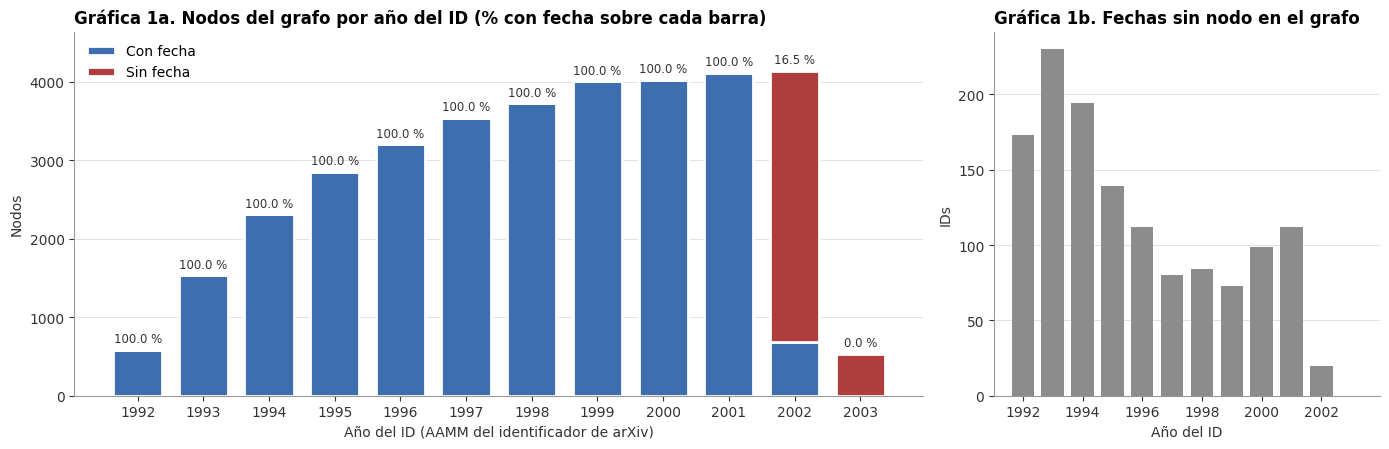

,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003
con fecha,582,1533,2308,2853,3202,3535,3723,4003,4025,4113,681,0
sin fecha,0,0,0,0,0,0,0,0,0,0,3456,532
fecha sin nodo,173,230,194,139,112,80,84,73,99,112,20,0
% nodos con fecha,100.0 %,100.0 %,100.0 %,100.0 %,100.0 %,100.0 %,100.0 %,100.0 %,100.0 %,100.0 %,16.5 %,0.0 %


In [15]:
# Gráfica 1. Cobertura de fechas por año del ID: nodos del grafo con y sin fecha, y fechas sin nodo
anio_nodo = pd.Series(partes_arxiv(nodos_grafo.to_series())["anio"].to_numpy(), index=nodos_grafo)
anio_fecha_sin_nodo = pd.Series(partes_arxiv(fechas_sin_nodo.to_series())["anio"].to_numpy(), index=fechas_sin_nodo)
cobertura = pd.DataFrame({
    "con fecha": anio_nodo[anio_nodo.index.isin(ids_fecha)].value_counts(),
    "sin fecha": anio_nodo[~anio_nodo.index.isin(ids_fecha)].value_counts(),
    "fecha sin nodo": anio_fecha_sin_nodo.value_counts(),
}).fillna(0).astype(int).sort_index()
cobertura["% nodos con fecha"] = cobertura["con fecha"] / (cobertura["con fecha"] + cobertura["sin fecha"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
x = cobertura.index
ax1.bar(x, cobertura["con fecha"], color=AZUL, width=0.75, edgecolor="white", linewidth=2, label="Con fecha")
ax1.bar(x, cobertura["sin fecha"], bottom=cobertura["con fecha"], color=ROJO, width=0.75,
        edgecolor="white", linewidth=2, label="Sin fecha")
for anio, fila in cobertura.iterrows():
    ax1.text(anio, fila["con fecha"] + fila["sin fecha"] + 60, pct(fila["% nodos con fecha"], 1),
             ha="center", va="bottom", fontsize=8.5, color=TINTA)
ax1.set_xticks(x)
ax1.set_ylim(0, (cobertura["con fecha"] + cobertura["sin fecha"]).max() * 1.12)
estilo_ejes(ax1, "Gráfica 1a. Nodos del grafo por año del ID (% con fecha sobre cada barra)",
            "Año del ID (AAMM del identificador de arXiv)", "Nodos")
ax1.legend(loc="upper left")

ax2.bar(x, cobertura["fecha sin nodo"], color=GRIS, width=0.75)
ax2.set_xticks(x[::2])
estilo_ejes(ax2, "Gráfica 1b. Fechas sin nodo en el grafo", "Año del ID", "IDs")
plt.tight_layout()
plt.show()

display(cobertura.assign(**{"% nodos con fecha": cobertura["% nodos con fecha"].map(lambda v: pct(v, 1))}).T)

In [16]:
# Nodos sin fecha: en qué años caen y qué papel tienen en el grafo (solo citan, solo son citados o ambos)
def papel(ids):
    """
    Clasifica nodos según tengan aristas de salida, de entrada o ambas.

    Parámetros
    ----------
    ids : pd.Index
        IDs de los nodos.

    Retorna
    -------
    pd.Series
        Etiqueta 'cita y es citado', 'solo cita' o 'solo es citado' por nodo.
    """
    sal = ids.isin(grado_sal.index)
    ent = ids.isin(grado_ent.index)
    return pd.Series(np.select([sal & ent, sal], ["cita y es citado", "solo cita"], "solo es citado"), index=ids)


partes_sin = partes_arxiv(nodos_sin_fecha.to_series())
en_corte = partes_sin["anio"].ge(2002)
print(f"Nodos sin fecha con ID de 2002–2003: {en_corte.sum():,} de {len(nodos_sin_fecha):,} ({pct(en_corte.mean())}) "
      f"| con ID anterior a 2002: {(~en_corte).sum():,}")
print(f"Nodos sin fecha de 2002, por mes del ID: "
      f"{partes_sin.loc[partes_sin['anio'] == 2002, 'mes'].value_counts().sort_index().to_dict()}")

comparacion = pd.DataFrame({
    "nodos": [len(enlazados), len(nodos_sin_fecha)],
    "grado de salida mediano": [grado_sal.reindex(enlazados, fill_value=0).median(),
                                grado_sal.reindex(nodos_sin_fecha, fill_value=0).median()],
    "grado de entrada mediano": [grado_ent.reindex(enlazados, fill_value=0).median(),
                                 grado_ent.reindex(nodos_sin_fecha, fill_value=0).median()],
}, index=["con fecha", "sin fecha"])
display(comparacion)
display(pd.crosstab(np.where(en_corte, "ID de 2002–2003", "ID anterior a 2002"),
                    papel(nodos_sin_fecha).to_numpy(), rownames=["año del ID"], colnames=["papel en el grafo"],
                    margins=True, margins_name="Total"))

Nodos sin fecha con ID de 2002–2003: 3,988 de 3,988 (100.00 %) | con ID anterior a 2002: 0
Nodos sin fecha de 2002, por mes del ID: {3: 163, 4: 356, 5: 340, 6: 302, 7: 361, 8: 275, 9: 370, 10: 438, 11: 452, 12: 399}


,nodos,grado de salida mediano,grado de entrada mediano
con fecha,30558,7.0,5.0
sin fecha,3988,13.0,1.0


papel en el grafo,cita y es citado,solo cita,solo es citado,Total
año del ID,,,,
ID de 2002–2003,2163,1790,35,3988
Total,2163,1790,35,3988


**Observaciones: completitud y enlace de registros**

- **Cobertura.** **30,558** de los **34,546** nodos tienen fecha (**88.46 %**) y **3,988** no (**11.54 %**). Sobre las
  aristas, el **82.37 %** (**347,268**) tiene la fecha de sus dos extremos, el **15.55 %** solo una y el **2.08 %** ninguna.
- **La falta de fechas no es aleatoria: es un corte en el tiempo (Gráfica 1a).** Los nodos con ID de 1992 a 2001 tienen
  fecha en el **100.0 %**. Los **3,988** nodos sin fecha son **todos** de 2002–2003:
  - en 2002 solo tiene fecha el **16.5 %** (**681** nodos, de enero a marzo);
  - en 2003, ninguno.

  Coincide con la última fecha del archivo (**12/03/2002**). El grafo llega hasta 2003-02, pero el archivo de fechas se
  cortó once meses antes.
- **El corte se nota en los grados.** Los nodos sin fecha tienen un grado de salida mediano de **13** (contra **7** de
  los fechados) y un grado de entrada mediano de **1** (contra **5**). Son artículos recientes, que ya citan su
  bibliografía completa pero han tenido poco tiempo para ser citados: **1,790** de ellos solo citan y apenas **35** solo
  son citados.
- **Fechas sin nodo (Gráfica 1b).** **1,316** IDs con fecha (**4.13 %** de las fechas propias) no aparecen en ninguna
  arista: son artículos de `hep-ph` que no citan ni son citados por otro artículo del conjunto. SNAP no los incluye en el
  grafo y son más frecuentes en los primeros años (**230** en 1993), cuando había menos artículos anteriores a los cuales
  citar.

**Decisión: completitud**

- **Mes del ID como respaldo.** Cada nodo recibe dos columnas temporales:
  - `fecha`, la fecha exacta de envío, solo para los nodos enlazados;
  - `mes_id`, el año y mes que codifica su propio ID, para el **100 %** de los nodos.

  La columna `fecha_fuente` indica de dónde sale el dato temporal de cada nodo (`archivo de fechas` o `ID`). No es una
  imputación estadística: el `AAMM` lo asigna arXiv al numerar el artículo. La celda siguiente lo valida sobre los nodos
  que tienen ambos datos. Los análisis por año o cohorte (el sesgo por antigüedad del
  notebook 2) usan `mes_id`. Las citas al futuro medidas en días (sección 5) usan solo `fecha`.
- **Las 1,316 fechas sin nodo quedan fuera del grafo**, como en SNAP: el grafo se define por sus aristas, y como nodos
  aislados solo recibirían el puntaje de teletransportación de PageRank.

In [17]:
# Tabla de nodos con su fecha exacta (si la hay), el mes que codifica su ID y la fuente del dato temporal
nodos = pd.DataFrame(index=nodos_grafo.sort_values())
partes_nodos = partes_arxiv(nodos.index.to_series())
nodos["fecha"] = nodos.index.map(fecha_de)
nodos["mes_id"] = pd.PeriodIndex.from_fields(year=partes_nodos["anio"], month=partes_nodos["mes"], freq="M")
nodos["fecha_fuente"] = np.where(nodos["fecha"].notna(), "archivo de fechas", "ID")

# Validación sobre los nodos enlazados: diferencia en meses entre el mes del ID y el mes de la fecha real
con_ambas = nodos.dropna(subset=["fecha"])
dif_meses = (con_ambas["mes_id"] - con_ambas["fecha"].dt.to_period("M")).map(lambda d: d.n)
print(f"Nodos enlazados: {len(con_ambas):,} | mes del ID − mes de la fecha: "
      f"{dif_meses.value_counts().sort_index().to_dict()}")
print(f"Coinciden con 0 o 1 mes de diferencia: {pct(dif_meses.between(0, 1).mean())}")
display(nodos["fecha_fuente"].value_counts().rename("nodos").to_frame())
display(nodos.sample(5, random_state=42))

Nodos enlazados: 30,558 | mes del ID − mes de la fecha: {-12: 1, -1: 62, 0: 30321, 1: 165, 4: 1, 5: 1, 6: 1, 7: 1, 9: 1, 12: 3, 24: 1}
Coinciden con 0 o 1 mes de diferencia: 99.76 %


,nodos
fecha_fuente,
archivo de fechas,30558
ID,3988


,fecha,mes_id,fecha_fuente
id,,,
0205174,NaT,2002-05,ID
9710311,1997-10-10,1997-10,archivo de fechas
9705333,1997-05-16,1997-05,archivo de fechas
0204272,NaT,2002-04,ID
9912209,1999-12-01,1999-12,archivo de fechas


**Observaciones: validación del mes del ID**

- En los **30,558** nodos enlazados, el mes del ID coincide con el de la fecha en **30,321** casos y es el mes siguiente
  en **165**: el **99.76 %** cae en la tolerancia de 0 o 1 mes. Usar `mes_id` como respaldo tiene error de a lo más un
  mes en casi todos los nodos.
- **Discrepancias.** **62** nodos tienen un ID del mes **anterior** a su fecha y **10** difieren en 4 meses o más en valor
  absoluto (hasta **24**). Es un problema de **exactitud** (Unidad 2) de alguna de las dos fuentes: no se puede saber cuál está mal, así
  que no se corrigen. Para `mes_id` el efecto es despreciable.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CALIDAD</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Consistencia temporal</span></div>


La **consistencia** (Unidad 2) pide que los datos no se contradigan entre sí. En una red de citas hay una regla
implícita: un artículo solo puede citar artículos que ya existían cuando se escribió. Para cada arista *i → j* con las
dos fechas se define el **desfase**

$$\Delta_{ij} = \text{fecha}(j) - \text{fecha}(i) \quad \text{(en días)},$$

que normalmente es **negativo**: el citado es anterior al que cita. Si $\Delta_{ij} > 0$, el artículo *i* cita a uno
que se envió **después** que él: es una **cita al futuro**. En arXiv tienen una explicación conocida. La fecha del
archivo es la del **primer envío**, pero los autores pueden subir versiones revisadas (v2, v3…) con la bibliografía
actualizada, y las citas se extraen de la última versión.

Las autocitas se excluyen porque se eliminan en el preprocesamiento. La medición en días usa solo las aristas con las
dos fechas reales. Como complemento, se mide a nivel de mes con `mes_id` sobre **todas** las aristas.

Al final se revisan las **fechas fuera de rango** respecto al periodo que anuncia SNAP (enero de 1993 a abril de 2003).

In [18]:
# Desfase en días entre el citado y el que cita, y conteo de citas al futuro
citas = aristas.loc[~es_auto].assign(es_reciproca=es_reciproca[~es_auto])
citas["fecha_origen"] = citas["origen"].map(fecha_de)
citas["fecha_destino"] = citas["destino"].map(fecha_de)
citas["desfase_dias"] = (citas["fecha_destino"] - citas["fecha_origen"]).dt.days
citas["desfase_meses_id"] = (nodos["mes_id"].reindex(citas["destino"]).to_numpy()
                             - nodos["mes_id"].reindex(citas["origen"]).to_numpy())
citas["desfase_meses_id"] = citas["desfase_meses_id"].map(lambda d: d.n)

con_dos = citas.dropna(subset=["desfase_dias"])
d = con_dos["desfase_dias"]
m = citas["desfase_meses_id"]
temporal = pd.DataFrame({
    "aristas": [len(con_dos), len(citas)],
    "hacia el pasado": [(d < 0).sum(), (m < 0).sum()],
    "mismo día / mismo mes": [(d == 0).sum(), (m == 0).sum()],
    "al futuro": [(d > 0).sum(), (m > 0).sum()],
}, index=["en días (las dos fechas reales)", "en meses (mes_id, todas)"])
temporal["% al futuro"] = (temporal["al futuro"] / temporal["aristas"]).map(lambda v: pct(v, 3))
display(temporal)

futuro = con_dos[d > 0]
print(f"Desfase de las citas al futuro (días): mediana {futuro['desfase_dias'].median():.0f}, "
      f"p25 {futuro['desfase_dias'].quantile(0.25):.0f}, p75 {futuro['desfase_dias'].quantile(0.75):.0f}, "
      f"p90 {futuro['desfase_dias'].quantile(0.9):.0f}, máximo {futuro['desfase_dias'].max():.0f}")
print(f"Citas al futuro de hasta 30 días: {pct((futuro['desfase_dias'] <= 30).mean())} | "
      f"de hasta 365 días: {pct((futuro['desfase_dias'] <= 365).mean())}")
print(f"Desfase de las citas normales (días hacia atrás): mediana {-d[d < 0].median():.0f}, máximo {-d[d < 0].min():.0f}")

,aristas,hacia el pasado,mismo día / mismo mes,al futuro,% al futuro
en días (las dos fechas reales),347229,345362,283,1584,0.456 %
"en meses (mes_id, todas)",421534,414748,5171,1615,0.383 %


Desfase de las citas al futuro (días): mediana 123, p25 37, p75 502, p90 1206, máximo 3124
Citas al futuro de hasta 30 días: 22.35 % | de hasta 365 días: 70.58 %
Desfase de las citas normales (días hacia atrás): mediana 666, máximo 3627


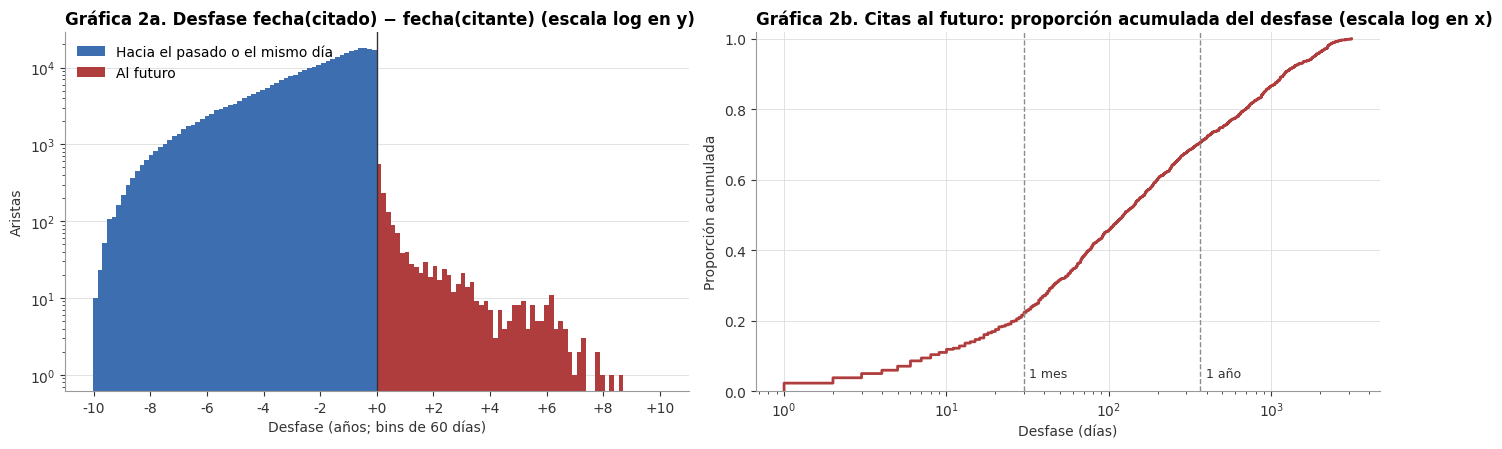

In [19]:
# Gráfica 2. Distribución del desfase entre citado y citante, y desfase acumulado de las citas al futuro
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
# Bordes en x.5 para que el bin de la derecha del 0 contenga solo desfases positivos
bordes = np.arange(-3660, 3661, 60) + 0.5
ax1.hist(d[d <= 0], bins=bordes, color=AZUL, label="Hacia el pasado o el mismo día")
ax1.hist(d[d > 0], bins=bordes, color=ROJO, label="Al futuro")
ax1.axvline(0, color=TINTA, linewidth=1)
ax1.set_yscale("log")
ax1.set_xticks(np.arange(-3650, 3651, 730), labels=[f"{a:+d}" for a in range(-10, 11, 2)])
estilo_ejes(ax1, "Gráfica 2a. Desfase fecha(citado) − fecha(citante) (escala log en y)",
            "Desfase (años; bins de 60 días)", "Aristas")
ax1.legend(loc="upper left")

lag = np.sort(futuro["desfase_dias"].to_numpy())
ax2.step(lag, np.arange(1, len(lag) + 1) / len(lag), where="post", color=ROJO, linewidth=2)
for dias, texto in [(30, "1 mes"), (365, "1 año")]:
    ax2.axvline(dias, color=GRIS, linestyle="--", linewidth=1)
    ax2.text(dias * 1.08, 0.04, texto, color=TINTA, fontsize=9)
ax2.set_xscale("log")
ax2.set_ylim(0, 1.02)
estilo_ejes(ax2, "Gráfica 2b. Citas al futuro: proporción acumulada del desfase (escala log en x)",
            "Desfase (días)", "Proporción acumulada", rejilla="both")
plt.tight_layout()
plt.show()

In [20]:
# Quién hace las citas al futuro: concentración por artículo citante y cruce con los pares recíprocos
por_origen = futuro.groupby("origen").size().sort_values(ascending=False)
print(f"Citas al futuro: {len(futuro):,} hechas por {len(por_origen):,} artículos | "
      f"el 10 % de esos artículos con más citas al futuro concentra {pct(por_origen.head(len(por_origen) // 10).sum() / len(futuro))}")
print(f"Citas al futuro dentro de un par recíproco: {futuro['es_reciproca'].sum():,} ({pct(futuro['es_reciproca'].mean())})")
rec_con_dos = con_dos[con_dos["es_reciproca"]]
print(f"Aristas recíprocas con las dos fechas: {len(rec_con_dos):,} | al futuro: {(rec_con_dos['desfase_dias'] > 0).sum():,} | "
      f"mismo día: {(rec_con_dos['desfase_dias'] == 0).sum():,}")

top = por_origen.head(8).rename("citas al futuro").to_frame()
top["grado de salida"] = top.index.map(grado_sal)
top["% de su bibliografía"] = (top["citas al futuro"] / top["grado de salida"]).map(lambda v: pct(v, 1))
top["fecha"] = top.index.map(fecha_de).strftime("%d/%m/%Y")
top["desfase máximo (días)"] = futuro.groupby("origen")["desfase_dias"].max().reindex(top.index).astype(int)
display(top)

Citas al futuro: 1,584 hechas por 1,100 artículos | el 10 % de esos artículos con más citas al futuro concentra 28.03 %
Citas al futuro dentro de un par recíproco: 466 (29.42 %)
Aristas recíprocas con las dos fechas: 1,052 | al futuro: 466 | mismo día: 120


,citas al futuro,grado de salida,% de su bibliografía,fecha,desfase máximo (días)
origen,,,,,
9806408,17,30,56.7 %,18/06/1998,1297
9810542,10,29,34.5 %,30/10/1998,279
9805419,10,15,66.7 %,22/05/1998,1176
9811498,8,45,17.8 %,28/11/1998,403
9811489,8,53,15.1 %,27/11/1998,242
0109085,7,14,50.0 %,10/09/2001,138
0102259,7,41,17.1 %,21/02/2001,14
9806301,7,25,28.0 %,08/06/1998,876


In [21]:
# Fechas fuera del periodo que anuncia SNAP (enero de 1993 a abril de 2003)
INICIO_SNAP, FIN_SNAP = pd.Timestamp("1993-01-01"), pd.Timestamp("2003-04-30")
rango = pd.DataFrame({
    "mínimo": [f"{fechas['fecha'].min():%d/%m/%Y}", f"{nodos['fecha'].min():%d/%m/%Y}", str(nodos["mes_id"].min())],
    "máximo": [f"{fechas['fecha'].max():%d/%m/%Y}", f"{nodos['fecha'].max():%d/%m/%Y}", str(nodos["mes_id"].max())],
    "antes de 1993-01": [(fechas["fecha"] < INICIO_SNAP).sum(), (nodos["fecha"] < INICIO_SNAP).sum(),
                         (nodos["mes_id"] < pd.Period("1993-01", "M")).sum()],
    "después de 2003-04": [(fechas["fecha"] > FIN_SNAP).sum(), (nodos["fecha"] > FIN_SNAP).sum(),
                           (nodos["mes_id"] > pd.Period("2003-04", "M")).sum()],
}, index=["fechas propias (archivo)", "fecha de los nodos del grafo", "mes_id de los nodos del grafo"])
display(rango)
print(f"Nodos con mes_id de 1992: {(nodos['mes_id'].dt.year == 1992).sum():,} | "
      f"aristas que salen de ellos: {citas['origen'].map(nodos['mes_id'].dt.year).eq(1992).sum():,}")

,mínimo,máximo,antes de 1993-01,después de 2003-04
fechas propias (archivo),11/02/1992,12/03/2002,755,0
fecha de los nodos del grafo,11/02/1992,12/03/2002,582,0
mes_id de los nodos del grafo,1992-03,2003-02,582,0


Nodos con mes_id de 1992: 582 | aristas que salen de ellos: 170


**Observaciones y decisión: consistencia temporal**

- **Las citas al futuro son raras.** De las **347,229** aristas con las dos fechas (sin autocitas), **345,362** apuntan
  al pasado, **283** al mismo día y **1,584** al futuro (**0.456 %**). A nivel de mes, con `mes_id` sobre las
  **421,534** aristas, son **1,615** (**0.383 %**): el corte de fechas de 2002 no esconde un problema mayor.
- **Su desfase es largo (Gráfica 2).** La mediana es de **123 días** (p25 **37**, p75 **502**, p90 **1,206**, máximo
  **3,124**). Solo el **22.35 %** cae dentro de un mes y el **70.58 %** dentro de un año. No parecen errores de captura de
  unos días: encajan con versiones revisadas que actualizan la bibliografía meses o años después del primer envío.
  En la Gráfica 2a, la cola roja decrece rápido y tiene un segundo grupo entre **+4 y +7 años**. En comparación, una
  cita normal mira a la mediana **666 días** hacia atrás.
- **Se concentran en pocos artículos.** Las **1,584** citas las hacen **1,100** artículos, y el 10 % de ellos con más
  citas al futuro reúne el **28.03 %**. El caso extremo es `9806408` (18/06/1998): **17** de sus **30** referencias
  (**56.7 %**) son al futuro, con un desfase de hasta **1,297** días, lo que sugiere una revisión muy posterior.
- **Explican los pares recíprocos.** De las **1,052** aristas recíprocas con las dos fechas, **466** son al futuro y
  **120** son del mismo día. Cada par con fechas distintas tiene exactamente una cita al futuro y los **60** pares
  restantes son artículos compañeros del mismo día. A su vez, el **29.42 %** de las citas al futuro pertenece a un par
  recíproco.
- **Fechas fuera de rango.** No hay nada posterior a abril de 2003, pero hay **582** nodos de **1992** (**755** fechas
  propias antes de 1993, contando las que no tienen nodo). Las fechas reales van del **11/02/1992** al **12/03/2002** y
  `mes_id` va de **1992-03** a **2003-02**. La descripción de SNAP ("enero de 1993 a abril de 2003") es imprecisa: el
  archivo `hep-ph` empezó en 1992 y esos artículos son válidos.

**Decisión.** Como se acordó, las citas al futuro **se conservan y se marcan** con `es_futuro` (y `desfase_dias`): son
citas reales de versiones revisadas y quitarlas cambiaría la bibliografía de artículos como `9806408`. Para los análisis
que dependen del orden temporal, el flujo marcado permite comparar con y sin ellas. Los **582** nodos de 1992 **se
conservan**: la discrepancia está en la descripción de SNAP, no en los datos.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · GRAFO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Estructura del grafo</span></div>


Se construye el grafo dirigido con `networkx.DiGraph` a partir de las citas **sin autocitas**. Quitar un lazo no cambia
las componentes conexas, así que estas siguen siendo comparables con las de SNAP. Se revisa lo que importa para
PageRank y HITS:

- **Grados.** El grado de entrada $k_{in}$ son las citas recibidas y el de salida $k_{out}$, el tamaño de la
  bibliografía dentro del conjunto. Las redes de citas suelen tener **colas pesadas**, que se ven como una recta
  aproximada en escala log-log.
- **Nodos colgantes** (*dangling*), con $k_{out} = 0$. Su columna de la matriz de transición $M$ es cero, así que en el
  método de potencias "pierden" puntaje en cada iteración. Es lo primero que hay que tratar en la etapa 2.
- **Nodos aislados**, con $k_{in} = k_{out} = 0$. No existen en una lista de aristas, pero se comprueba.
- **Componentes.** La débilmente conexa (WCC) ignora la dirección. En la fuertemente conexa (SCC), cada nodo alcanza a
  todos los demás siguiendo flechas. En una red de citas pura, que es un grafo acíclico, toda SCC tendría un solo nodo.
- **Reciprocidad y ciclos.** Una SCC grande es un hallazgo de calidad: indica ciclos, que en el tiempo solo pueden
  existir si hay citas al futuro (sección 5).

In [22]:
# Grafo dirigido sin autocitas y resumen estructural comparado con SNAP
G = nx.from_pandas_edgelist(citas, "origen", "destino", create_using=nx.DiGraph)
k_in = pd.Series(dict(G.in_degree()), name="k_in")
k_out = pd.Series(dict(G.out_degree()), name="k_out")
wcc = sorted((len(c) for c in nx.weakly_connected_components(G)), reverse=True)
scc = sorted((len(c) for c in nx.strongly_connected_components(G)), reverse=True)

estructura = pd.DataFrame({
    "este notebook": [f"{G.number_of_nodes():,}", f"{G.number_of_edges():,}", f"{len(wcc):,}", f"{wcc[0]:,}",
                      f"{len(scc):,}", f"{scc[0]:,}", f"{sum(t > 1 for t in scc):,}",
                      f"{nx.reciprocity(G):.5f}", f"{(k_out == 0).sum():,} ({pct((k_out == 0).mean())})",
                      f"{(k_in == 0).sum():,} ({pct((k_in == 0).mean())})", f"{((k_in == 0) & (k_out == 0)).sum():,}"],
    "SNAP": ["34,546", "421,578", "", "34,401", "", "12,711", "", "", "", "", ""],
}, index=["Nodos", "Aristas", "WCC (número)", "WCC mayor (nodos)", "SCC (número)", "SCC mayor (nodos)",
          "SCC con más de un nodo", "Reciprocidad", "Colgantes (k_out = 0)", "Nunca citados (k_in = 0)", "Aislados"])
display(estructura)
print(f"Tamaños de las 5 WCC mayores: {wcc[:5]} | de las 5 SCC mayores: {scc[:5]}")

,este notebook,SNAP
Nodos,"34,546","34,546"
Aristas,"421,534","421,578"
WCC (número),61,
WCC mayor (nodos),"34,401","34,401"
SCC (número),"21,608",
SCC mayor (nodos),"12,711","12,711"
SCC con más de un nodo,143,
Reciprocidad,0.00312,
Colgantes (k_out = 0),"2,393 (6.93 %)",
Nunca citados (k_in = 0),"6,320 (18.29 %)",


Tamaños de las 5 WCC mayores: [34401, 6, 5, 5, 5] | de las 5 SCC mayores: [12711, 11, 9, 8, 6]


In [23]:
# Diámetro aproximado: BFS desde 100 nodos al azar de la WCC mayor, sobre el grafo no dirigido
U = G.subgraph(max(nx.weakly_connected_components(G), key=len)).to_undirected()
rng = np.random.default_rng(42)
fuentes = rng.choice(np.array(U.nodes), size=100, replace=False)
distancias = np.concatenate([np.fromiter(nx.single_source_shortest_path_length(U, f).values(), dtype=int)
                             for f in fuentes])
print(f"Excentricidad máxima en la muestra (cota inferior del diámetro): {distancias.max()} (SNAP: 12)")
print(f"Distancia mediana: {np.median(distancias):.0f} | percentil 90 (diámetro efectivo aproximado): "
      f"{np.percentile(distancias, 90):.1f}")

Excentricidad máxima en la muestra (cota inferior del diámetro): 11 (SNAP: 12)
Distancia mediana: 4 | percentil 90 (diámetro efectivo aproximado): 6.0


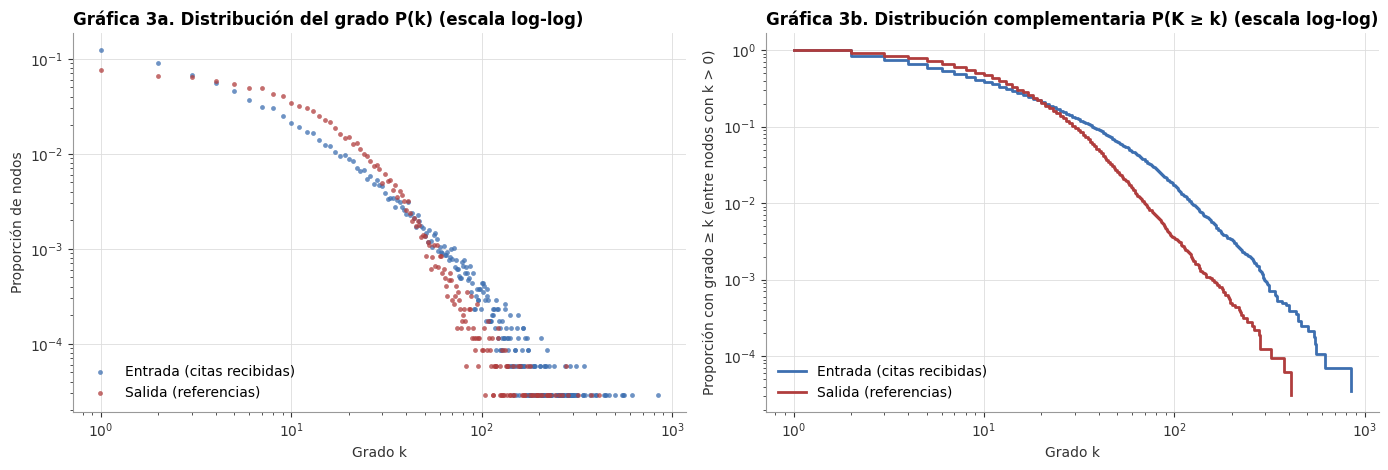

,media,mediana,p90,p99,máximo,% de ceros,asimetría
entrada (k_in),12.2,4.0,31.0,113.0,846.0,18.29,7.42
salida (k_out),12.2,8.0,28.0,67.0,411.0,6.93,5.13


In [24]:
# Gráfica 3. Distribución de los grados de entrada y de salida en escala log-log
def ccdf(valores):
    """
    Función de distribución complementaria empírica P(K ≥ k) para valores enteros positivos.

    Parámetros
    ----------
    valores : array-like
        Grados (se ignoran los ceros, que no caben en escala log).

    Retorna
    -------
    tuple of (np.ndarray, np.ndarray)
        Valores distintos k y la proporción de observaciones con valor ≥ k.
    """
    v = np.sort(np.asarray(valores)[np.asarray(valores) > 0])
    k, primera = np.unique(v, return_index=True)
    return k, 1 - primera / len(v)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for serie, color, etiqueta in [(k_in, AZUL, "Entrada (citas recibidas)"), (k_out, ROJO, "Salida (referencias)")]:
    frec = serie[serie > 0].value_counts().sort_index()
    ax1.scatter(frec.index, frec.values / len(serie), s=12, color=color, alpha=0.75, label=etiqueta, linewidths=0)
    k, p = ccdf(serie)
    ax2.step(k, p, where="post", color=color, linewidth=2, label=etiqueta)
for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.legend(loc="lower left")
estilo_ejes(ax1, "Gráfica 3a. Distribución del grado P(k) (escala log-log)", "Grado k", "Proporción de nodos", rejilla="both")
estilo_ejes(ax2, "Gráfica 3b. Distribución complementaria P(K ≥ k) (escala log-log)", "Grado k",
            "Proporción con grado ≥ k (entre nodos con k > 0)", rejilla="both")
plt.tight_layout()
plt.show()

resumen_grado = pd.DataFrame({
    nombre: {"media": s.mean(), "mediana": s.median(), "p90": s.quantile(0.9), "p99": s.quantile(0.99),
             "máximo": s.max(), "% de ceros": 100 * (s == 0).mean(), "asimetría": s.skew()}
    for nombre, s in [("entrada (k_in)", k_in), ("salida (k_out)", k_out)]
}).T
display(resumen_grado.round(2))

In [25]:
# Ciclos: tamaño de la SCC mayor al quitar las citas al futuro
futuro_dias = citas["desfase_dias"] > 0
futuro_mes = citas["desfase_meses_id"] > 0
futuro_comb = futuro_dias | (citas["desfase_dias"].isna() & futuro_mes)
mismo_mes = citas["desfase_meses_id"] == 0


def scc_sin(mascara, nombre):
    """
    Resume las SCC del grafo de citas después de quitar las aristas marcadas.

    Parámetros
    ----------
    mascara : pd.Series
        Booleana sobre `citas`; True = arista que se quita.
    nombre : str
        Descripción del escenario.

    Retorna
    -------
    pd.Series
        Aristas quitadas, SCC mayor, número de SCC con más de un nodo y si el grafo resultante es acíclico.
    """
    H = nx.from_pandas_edgelist(citas.loc[~mascara], "origen", "destino", create_using=nx.DiGraph)
    tam = sorted((len(c) for c in nx.strongly_connected_components(H)), reverse=True)
    return pd.Series({"aristas quitadas": f"{mascara.sum():,}", "SCC mayor": tam[0],
                      "SCC con más de un nodo": sum(t > 1 for t in tam),
                      "acíclico": nx.is_directed_acyclic_graph(H)}, name=nombre)


display(pd.DataFrame([
    scc_sin(pd.Series(False, index=citas.index), "grafo completo"),
    scc_sin(futuro_dias, "sin futuro (días, solo aristas con dos fechas)"),
    scc_sin(futuro_comb, "sin futuro (días o, si falta la fecha, mes_id)"),
    scc_sin(futuro_comb | mismo_mes, "sin futuro y sin citas del mismo mes"),
]))

,aristas quitadas,SCC mayor,SCC con más de un nodo,acíclico
grafo completo,0,12711,143,False
"sin futuro (días, solo aristas con dos fechas)","1,584",10218,92,False
"sin futuro (días o, si falta la fecha, mes_id)","1,852",4,95,False
sin futuro y sin citas del mismo mes,"6,809",1,0,True


**Observaciones: estructura del grafo**

- **La estructura coincide con SNAP.** Hay **34,546** nodos, **61** WCC con una mayor de **34,401** nodos (las demás
  tienen 6 nodos o menos) y una SCC mayor de **12,711** nodos. Las **421,534** aristas son las 421,578 de SNAP menos las
  **44** autocitas.
- **Distancias.** En una muestra de 100 BFS sobre el grafo no dirigido, la excentricidad máxima es **11**, una cota
  inferior del diámetro de **12** que publica SNAP. La distancia mediana es **4** y el percentil 90 es **6**: es una
  red de "mundo pequeño".
- **Grados con colas pesadas (Gráfica 3).** Los dos grados tienen media **12.2** (cada arista suma uno a cada lado),
  pero las medianas son **4** (entrada) y **8** (salida), y las asimetrías **7.42** y **5.13**.
  - La cola de **entrada** es la más pesada: p99 de **113** y máximo de **846** citas, casi en línea recta en la
    Gráfica 3b. Pocos artículos concentran muchas citas, y eso es lo que PageRank y HITS deben distinguir.
  - La de **salida** cae más rápido (p99 **67**, máximo **411**): una bibliografía tiene un tamaño limitado.
- **Nodos colgantes: 2,393** (**6.93 %**) no citan a ningún artículo del conjunto. En la matriz de transición $M$ su
  columna es cero y hay que tratarlos en la etapa 2. **6,320** (**18.29 %**) nunca son citados, y no hay aislados.
- **La reciprocidad es 0.00312**, que equivale a las **1,314** aristas recíprocas de la sección 3.
- **Hallazgo: la SCC gigante la crean las citas al futuro.** Una red de citas sin errores sería acíclica y no tendría
  SCC de más de un nodo:
  - quitando solo las **1,584** citas al futuro medidas en días, la SCC mayor baja a **10,218**, porque quedan las de los
    nodos de 2002–2003 sin fecha;
  - quitando también esas, con `mes_id` (**1,852** aristas en total), la SCC mayor baja a **4** nodos;
  - quitando además las citas del mismo mes (**6,809** aristas en total), el grafo es **acíclico**: los ciclos que
    quedan son entre artículos del mismo mes.

  Para la etapa 2, esto implica que casi todo el grafo es un DAG: el puntaje de PageRank fluye hacia los artículos
  viejos y solo vuelve hacia los nuevos por las citas al futuro y por la teletransportación.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CALIDAD</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. Atípicos de grado</span></div>


La Unidad 3 presenta tres detectores de atípicos:

- **IQR:** es atípico lo que queda fuera de $[Q_1 - 1.5\,\mathrm{IQR},\; Q_3 + 1.5\,\mathrm{IQR}]$. No supone normalidad.
- **3σ:** es atípico lo que queda fuera de $\bar{x} \pm 3s$. Supone que los datos son aproximadamente normales.
- **Isolation Forest:** aísla cada punto con cortes al azar. Los atípicos se aíslan con pocos cortes.

Con colas pesadas (sección 6), las dos reglas univariadas **engañan sobre el grado crudo**:

- el IQR se calcula con el grueso de los datos, que tiene grados pequeños, así que marca como atípica **toda** la cola;
- en 3σ, la propia cola infla la media y la desviación, y el umbral termina dependiendo de unos pocos nodos extremos.

La solución de la Unidad 5 es una **transformación logarítmica**, $x' = \log(1 + k)$, que comprime la cola y vuelve
la distribución más simétrica. El $+1$ permite incluir los grados 0. Las reglas se aplican después sobre $x'$.

En una red de citas, un grado extremo **no es un error**: es justo la señal que buscan PageRank y HITS. Esta sección
sirve para describir los extremos y verificar que sean artículos reales, no para eliminarlos.

In [26]:
# Límites y conteos de atípicos por IQR y 3σ, sobre el grado crudo y sobre log(1 + k)
def limites_atipicos(x):
    """
    Calcula los límites superiores de las reglas IQR (1.5·IQR) y 3σ y cuántos valores los superan.

    Parámetros
    ----------
    x : pd.Series
        Valores numéricos.

    Retorna
    -------
    dict
        Asimetría, límites superiores y número de atípicos por cada regla.
    """
    q1, q3 = x.quantile([0.25, 0.75])
    lim_iqr = q3 + 1.5 * (q3 - q1)
    lim_3s = x.mean() + 3 * x.std()
    return {"asimetría": x.skew(), "límite IQR": lim_iqr, "atípicos IQR": int((x > lim_iqr).sum()),
            "límite 3σ": lim_3s, "atípicos 3σ": int((x > lim_3s).sum())}


grados = pd.DataFrame({"k_in": k_in, "k_out": k_out}).reindex(nodos.index)
log_grados = np.log1p(grados)
filas = {}
for col in ["k_in", "k_out"]:
    for escala, serie in [("crudo", grados[col]), ("log(1 + k)", log_grados[col])]:
        filas[(col, escala)] = limites_atipicos(serie)
tabla_at = pd.DataFrame(filas).T
tabla_at[["atípicos IQR", "atípicos 3σ"]] = tabla_at[["atípicos IQR", "atípicos 3σ"]].astype(int)
for escala_log in ["límite IQR", "límite 3σ"]:
    # El límite en escala log se traduce al grado equivalente para poder compararlo
    tabla_at[f"{escala_log} (en grado)"] = [v if e == "crudo" else np.expm1(v)
                                           for (_, e), v in tabla_at[escala_log].items()]
tabla_at["% atípicos IQR"] = (tabla_at["atípicos IQR"] / len(grados)).map(pct)
tabla_at["% atípicos 3σ"] = (tabla_at["atípicos 3σ"] / len(grados)).map(pct)
display(tabla_at[["asimetría", "límite IQR (en grado)", "atípicos IQR", "% atípicos IQR",
                  "límite 3σ (en grado)", "atípicos 3σ", "% atípicos 3σ"]].round(2))

asimetría  límite IQR (en grado)  atípicos IQR % atípicos IQR  límite 3σ (en grado)  atípicos 3σ % atípicos 3σ
k_in  crudo            7.42                  31.00          3368         9.75 %                 88.20          610        1.77 %
      log(1 + k)       0.38                 258.28            50         0.14 %                248.51           56        0.16 %
k_out crudo            5.13                  35.50          2027         5.87 %                 57.87          560        1.62 %
      log(1 + k)      -0.22                 147.95            34         0.10 %                177.46           24        0.07 %

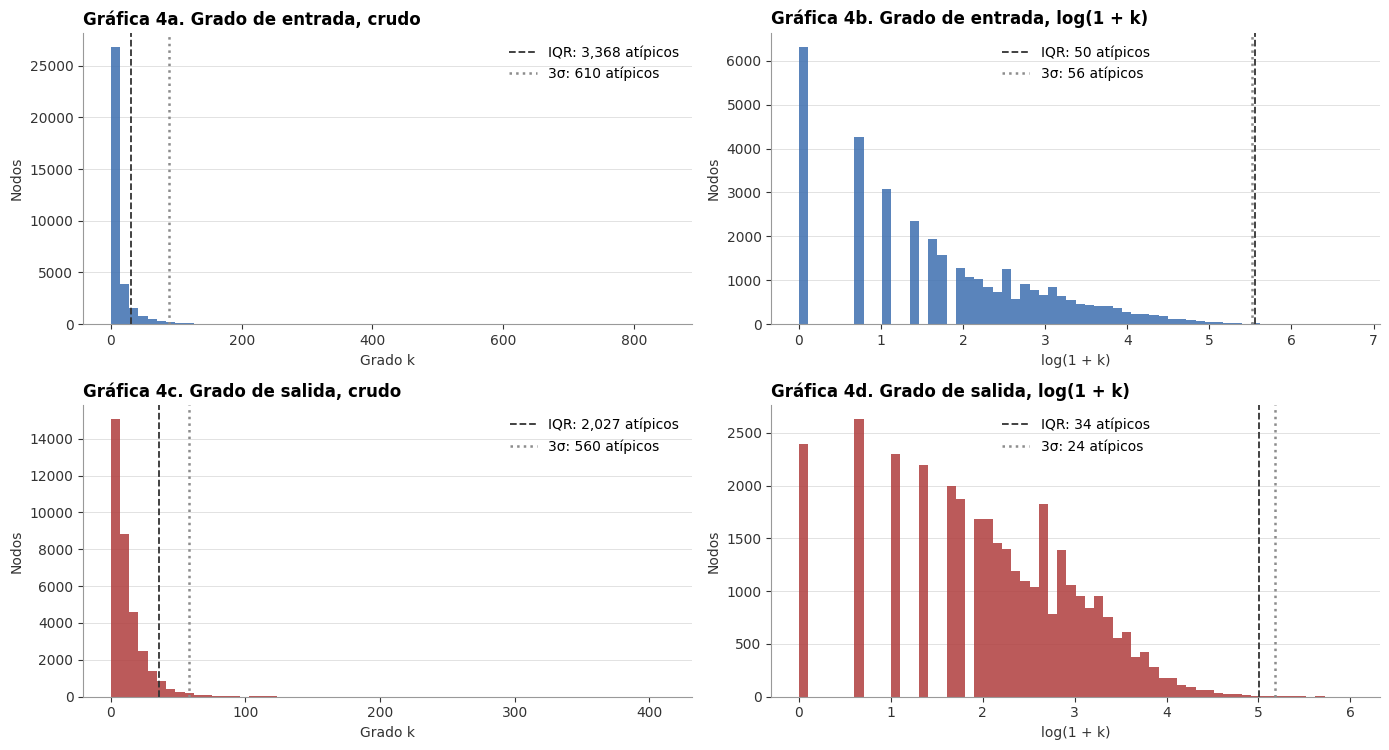

In [27]:
# Gráfica 4. Histograma del grado crudo y en log(1 + k), con los límites de IQR y 3σ
fig, ejes = plt.subplots(2, 2, figsize=(14, 7.6))
for fila, col, nombre in [(0, "k_in", "entrada"), (1, "k_out", "salida")]:
    for columna, escala, serie in [(0, "crudo", grados[col]), (1, "log(1 + k)", log_grados[col])]:
        ax = ejes[fila, columna]
        ax.hist(serie, bins=60, color=AZUL if col == "k_in" else ROJO, alpha=0.85)
        lim = tabla_at.loc[(col, escala)]
        ax.axvline(lim["límite IQR"], color=TINTA, linestyle="--", linewidth=1.3,
                   label=f"IQR: {int(lim['atípicos IQR']):,} atípicos")
        ax.axvline(lim["límite 3σ"], color=GRIS, linestyle=":", linewidth=1.8,
                   label=f"3σ: {int(lim['atípicos 3σ']):,} atípicos")
        ax.legend(loc="upper right" if escala == "crudo" else "upper center")
        letra = "abcd"[2 * fila + columna]
        etiqueta_x = "Grado k" if escala == "crudo" else "log(1 + k)"
        estilo_ejes(ax, f"Gráfica 4{letra}. Grado de {nombre}, {escala}", etiqueta_x, "Nodos")
plt.tight_layout()
plt.show()

Isolation Forest con contamination='auto': 13,390 nodos (38.76 %)


Isolation Forest con contamination=0.01 marca 346 nodos (1.00 %)
Por tipo de extremo:


IQR log k_in      False       True 
IQR log k_out     False True  False
Isolation Forest                   
False             34186    14     0
True                276    20    50

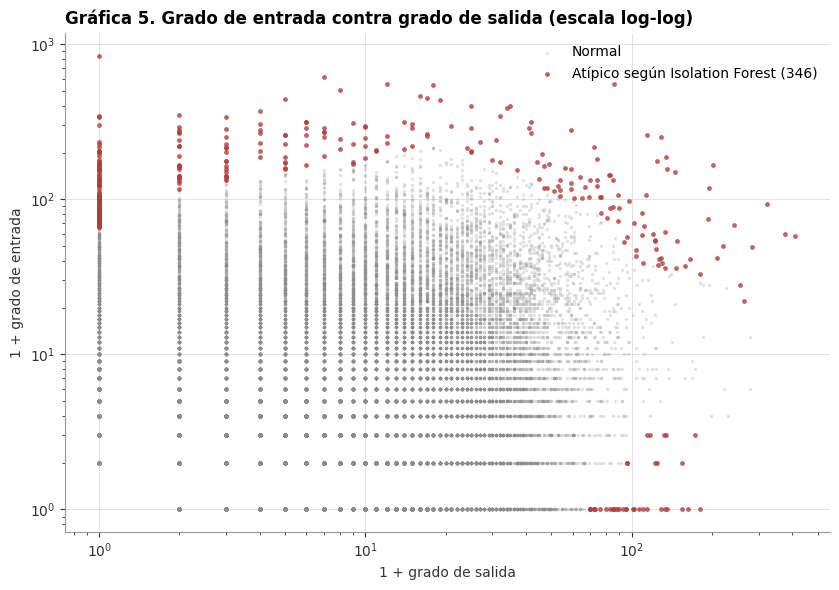

In [28]:
# Isolation Forest sobre (log(1 + k_in), log(1 + k_out)) como contraste multivariado
from sklearn.ensemble import IsolationForest

X_log = log_grados[["k_in", "k_out"]].to_numpy()
# Con el umbral automático (contamination="auto") se ve que no funciona con grados discretos y muy repetidos
auto = IsolationForest(n_estimators=200, contamination="auto", random_state=42).fit_predict(X_log)
print(f"Isolation Forest con contamination='auto': {(auto == -1).sum():,} nodos ({pct((auto == -1).mean())})")
# Se fija la proporción esperada de atípicos en 1 %, comparable con lo que marcan las reglas en escala log
iforest = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)
grados["atipico_if"] = iforest.fit_predict(X_log) == -1
grados["atipico_iqr_log_in"] = log_grados["k_in"] > tabla_at.loc[("k_in", "log(1 + k)"), "límite IQR"]
grados["atipico_iqr_log_out"] = log_grados["k_out"] > tabla_at.loc[("k_out", "log(1 + k)"), "límite IQR"]
print(f"Isolation Forest con contamination=0.01 marca {grados['atipico_if'].sum():,} nodos ({pct(grados['atipico_if'].mean())})")
print("Por tipo de extremo:")
display(pd.crosstab(grados["atipico_if"], [grados["atipico_iqr_log_in"], grados["atipico_iqr_log_out"]],
                    rownames=["Isolation Forest"], colnames=["IQR log k_in", "IQR log k_out"]))

fig, ax = plt.subplots(figsize=(8.5, 6))
normales = grados[~grados["atipico_if"]]
atipicos = grados[grados["atipico_if"]]
ax.scatter(normales["k_out"] + 1, normales["k_in"] + 1, s=6, color=GRIS, alpha=0.25, linewidths=0, label="Normal")
ax.scatter(atipicos["k_out"] + 1, atipicos["k_in"] + 1, s=12, color=ROJO, alpha=0.8, linewidths=0,
           label=f"Atípico según Isolation Forest ({len(atipicos):,})")
ax.set_xscale("log")
ax.set_yscale("log")
estilo_ejes(ax, "Gráfica 5. Grado de entrada contra grado de salida (escala log-log)",
            "1 + grado de salida", "1 + grado de entrada", rejilla="both")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [29]:
# Los artículos más extremos: más citados y con bibliografía más larga
extremos = grados.join(nodos[["fecha", "mes_id"]])
cols = ["k_in", "k_out", "mes_id", "fecha", "atipico_if"]
print("Top 8 por grado de entrada (más citados):")
display(extremos.nlargest(8, "k_in")[cols])
print("Top 8 por grado de salida (bibliografía más larga dentro del conjunto):")
display(extremos.nlargest(8, "k_out")[cols])
print(f"Años del ID de los 100 más citados: "
      f"{extremos.nlargest(100, 'k_in')['mes_id'].dt.year.value_counts().sort_index().to_dict()}")

Top 8 por grado de entrada (más citados):


,k_in,k_out,mes_id,fecha,atipico_if
id,,,,,
9803315,846,0,1998-03,1998-03-11,True
9804398,616,6,1998-04,1998-04-24,True
9407339,557,11,1994-07,1994-07-20,True
9512380,550,85,1995-12,1995-12-15,True
9606399,542,17,1996-06,1996-06-21,True
9807344,503,7,1998-07,1998-07-12,True
9306320,464,15,1993-06,1993-06-26,True
9905221,449,16,1999-05,1999-05-04,True


Top 8 por grado de salida (bibliografía más larga dentro del conjunto):


,k_in,k_out,mes_id,fecha,atipico_if
id,,,,,
0201071,57,411,2002-01,2002-01-10,True
0101336,59,376,2001-01,2001-01-30,True
0003154,93,322,2000-03,2000-03-16,True
0005025,48,282,2000-05,2000-05-03,True
0207108,12,278,2002-07,NaT,False
0209244,5,278,2002-09,NaT,False
0208209,21,263,2002-08,NaT,True
0202122,27,255,2002-02,2002-02-13,True


Años del ID de los 100 más citados: {1992: 8, 1993: 23, 1994: 14, 1995: 13, 1996: 12, 1997: 5, 1998: 21, 1999: 3, 2000: 1}


**Observaciones y decisión: atípicos de grado**

- **Sobre el grado crudo, las reglas engañan (Gráficas 4a y 4c).**
  - El IQR marca **3,368** nodos por entrada (**9.75 %**, límite de **31** citas) y **2,027** por salida (**5.87 %**,
    límite de **35.5**). Es toda la cola, no un puñado de casos raros.
  - Con 3σ son **610** y **560** nodos, con límites de **88.2** y **57.87**. La asimetría (**7.42** y **5.13**) muestra
    que la normalidad que supone 3σ no se cumple.
- **En escala log, las dos reglas coinciden (Gráficas 4b y 4d).** $\log(1 + k)$ deja la asimetría en **0.38**
  (entrada) y **−0.22** (salida).
  - Por entrada, el IQR marca **50** nodos (**0.14 %**, más de **258** citas) y 3σ **56** (**0.16 %**, más de **248.5**).
  - Por salida, **34** (**0.10 %**, más de **148** referencias) y **24** (**0.07 %**, más de **177**).
- **Isolation Forest.**
  - Con `contamination="auto"` marca **13,390** nodos (**38.76 %**): con grados discretos y muy repetidos, su umbral
    automático no sirve.
  - Con una proporción fija de **1 %** marca **346** nodos. Incluye a los **50** extremos de entrada y a **20** de los
    **34** de salida.
  - Los otros **276** son **combinaciones** raras de los dos grados que ninguna regla univariada ve (Gráfica 5):
    artículos muy citados que no citan a nadie del conjunto ($k_{out} = 0$), bibliografías largas sin ninguna cita
    recibida y nodos extremos en los dos grados.
- **Los extremos son artículos reales.**
  - El más citado, `9803315` (marzo de 1998), tiene **846** citas y **ningún** enlace de salida: es un nodo colgante.
    Le siguen `9804398` (**616**) y `9407339` (**557**).
  - Los **100** más citados tienen IDs de **1992 a 2000**: **23** de 1993, **21** de 1998 y solo **1** de 2000. Es un
    adelanto del sesgo por antigüedad del notebook 2.
  - Las bibliografías más largas son de 2000–2002 (`0201071`, con **411** referencias) y tienen el perfil de un
    artículo de revisión: candidatos a *hubs* en HITS.

**Decisión: los atípicos de grado se conservan.** No son errores de captura, sino la señal que miden PageRank y HITS, y
quitarlos cambiaría el resultado que se quiere estudiar (Unidad 3: un atípico se elimina solo si es un error). Para
cualquier modelo que use el grado como variable se usará $\log(1 + k)$, como se hizo en T2 con `Quantity` y `Price`.

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · DATOS</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Volumen por mes</span></div>


La serie mensual muestra cuánta actividad hay en cada parte del periodo y si los extremos son comparables, como la
Gráfica 1 de T2. Se usa `mes_id`, que existe para todos los nodos (sección 4). La zona sombreada marca los meses
posteriores al **corte del archivo de fechas** (12/03/2002), en los que solo hay `mes_id`.

Para cada mes $t$ se cuentan:

- **artículos:** los nodos con `mes_id` $= t$;
- **citas hechas:** las aristas cuyo **citante** es del mes $t$, es decir, cuánto citan los artículos de ese mes;
- **citas recibidas:** las aristas cuyo **citado** es del mes $t$, es decir, cuánto han sido citados hasta el final de los datos.

La diferencia entre las dos últimas es lo que en la etapa 3 aparecerá como sesgo por antigüedad. Un artículo de 1993
tuvo diez años para acumular citas; uno de 2002, unos meses.

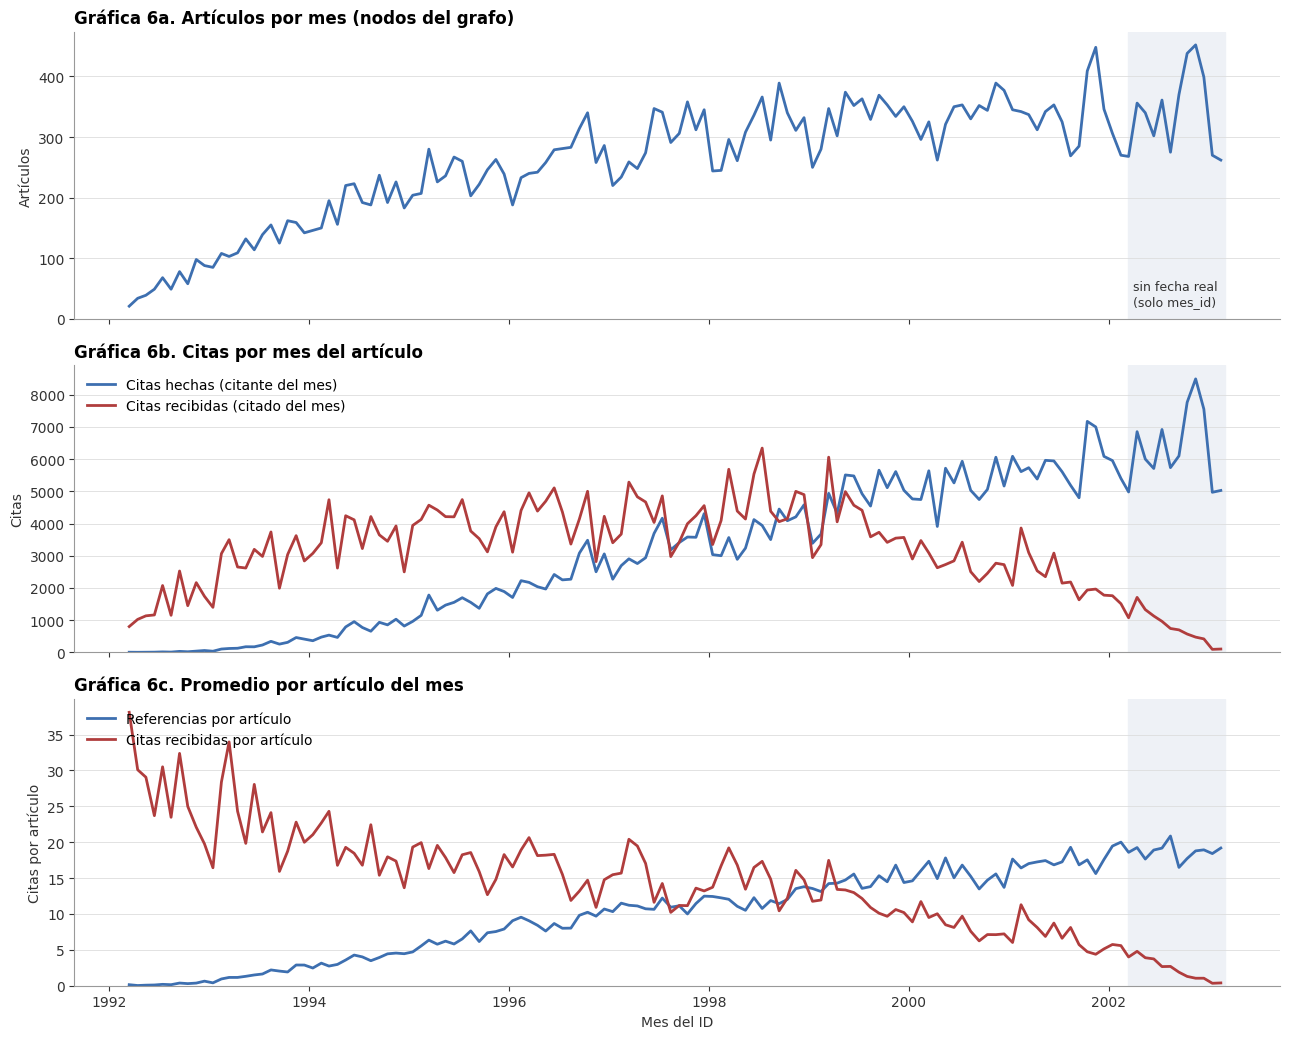

Meses: 132 (1992-03 a 2003-02) | meses sin artículos: 0
Artículos por mes: media 261.7, mínimo 21 (1992-03), máximo 452 (2002-11)


año del ID,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003
artículos,582,"1,533","2,308","2,853","3,202","3,535","3,723","4,003","4,025","4,113","4,137",532
citas hechas,170,"2,726","8,625","18,515","29,161","39,472","44,610","58,181","62,028","70,579","77,469","9,998"
citas recibidas,"15,219","34,634","43,147","48,903","50,559","49,937","56,020","48,212","33,719","28,634","12,356",194
referencias por artículo,0.3,1.8,3.7,6.5,9.1,11.2,12.0,14.5,15.4,17.2,18.7,18.8
citas recibidas por artículo,26.1,22.6,18.7,17.1,15.8,14.1,15.0,12.0,8.4,7.0,3.0,0.4


In [30]:
# Serie mensual de artículos, citas hechas y citas recibidas, por mes del ID
mes_origen = citas["origen"].map(nodos["mes_id"])
mes_destino = citas["destino"].map(nodos["mes_id"])
meses = pd.period_range(nodos["mes_id"].min(), nodos["mes_id"].max(), freq="M")
mensual = pd.DataFrame({
    "artículos": nodos["mes_id"].value_counts(),
    "citas hechas": mes_origen.value_counts(),
    "citas recibidas": mes_destino.value_counts(),
}).reindex(meses, fill_value=0)
mensual["referencias por artículo"] = mensual["citas hechas"] / mensual["artículos"]
mensual["citas recibidas por artículo"] = mensual["citas recibidas"] / mensual["artículos"]

CORTE_FECHAS = fechas["fecha"].max()
x_mes = mensual.index.to_timestamp() + pd.Timedelta(days=14)   # punto a mitad de mes

fig, ejes = plt.subplots(3, 1, figsize=(13, 10.5), sharex=True)
series = [
    (ejes[0], [("artículos", AZUL, "Artículos")], "Gráfica 6a. Artículos por mes (nodos del grafo)", "Artículos"),
    (ejes[1], [("citas hechas", AZUL, "Citas hechas (citante del mes)"),
               ("citas recibidas", ROJO, "Citas recibidas (citado del mes)")],
     "Gráfica 6b. Citas por mes del artículo", "Citas"),
    (ejes[2], [("referencias por artículo", AZUL, "Referencias por artículo"),
               ("citas recibidas por artículo", ROJO, "Citas recibidas por artículo")],
     "Gráfica 6c. Promedio por artículo del mes", "Citas por artículo"),
]
for ax, lineas, titulo, ylabel in series:
    ax.axvspan(CORTE_FECHAS, x_mes[-1] + pd.Timedelta(days=16), color=GRIS_CLARO, zorder=0)
    for col, color, etiqueta in lineas:
        ax.plot(x_mes, mensual[col], color=color, linewidth=2, label=etiqueta)
    ax.set_ylim(0, None)
    estilo_ejes(ax, titulo, None, ylabel)
    if len(lineas) > 1:
        ax.legend(loc="upper left")
ejes[0].text(CORTE_FECHAS + pd.Timedelta(days=20), mensual["artículos"].max() * 0.04,
             "sin fecha real\n(solo mes_id)", fontsize=9, color=TINTA, va="bottom")
ejes[2].set_xlabel("Mes del ID")
plt.tight_layout()
plt.show()

print(f"Meses: {len(mensual)} ({meses[0]} a {meses[-1]}) | meses sin artículos: {(mensual['artículos'] == 0).sum()}")
print(f"Artículos por mes: media {mensual['artículos'].mean():.1f}, mínimo {mensual['artículos'].min()} "
      f"({mensual['artículos'].idxmin()}), máximo {mensual['artículos'].max()} ({mensual['artículos'].idxmax()})")
anual = mensual.groupby(mensual.index.year)[["artículos", "citas hechas", "citas recibidas"]].sum()
anual["referencias por artículo"] = anual["citas hechas"] / anual["artículos"]
anual["citas recibidas por artículo"] = anual["citas recibidas"] / anual["artículos"]
tabla_anual = pd.concat([anual[["artículos", "citas hechas", "citas recibidas"]].map(lambda v: f"{v:,}"),
                         anual[["referencias por artículo", "citas recibidas por artículo"]].map(lambda v: f"{v:.1f}")],
                        axis=1)
display(tabla_anual.rename_axis("año del ID").T)

**Observaciones: volumen por mes**

- **Cobertura temporal.** Hay **132** meses, de **1992-03** a **2003-02**, y ninguno sin artículos. El primer mes
  tiene solo **21** artículos y el máximo es de **452** (**2002-11**), con una media de **261.7** al mes.
- **Crecimiento y meseta (Gráfica 6a).** El volumen crece de **1,533** artículos en 1993 a unos 4,000 al año desde
  1999 (**4,003** en 1999 y **4,137** en 2002). 1992 (**582**, desde marzo) y 2003 (**532**, solo enero y febrero) son
  años incompletos. En la zona sombreada el volumen sigue igual: al grafo no le faltan nodos ahí, solo les falta la
  fecha exacta (sección 4).
- **Doble censura de las citas (Gráficas 6b y 6c).** Es el hallazgo temporal más importante para las etapas siguientes.
  - **Hacia atrás:** las referencias por artículo dentro del conjunto suben de **0.3** (1992) y **1.8** (1993) a
    **18.7** (2002). Los primeros artículos sí citan, pero a trabajos anteriores a arXiv, que no están en el grafo.
  - **Hacia adelante:** las citas recibidas por artículo bajan de **26.1** (1992) y **22.6** (1993) a **3.0** (2002) y
    **0.4** (2003). Los artículos recientes no tuvieron tiempo de ser citados antes de que terminaran los datos.
    En total, las citas recibidas alcanzan su máximo en **1998** (**56,020**).
  - **Consecuencia:** el grado de entrada, y con él PageRank, favorece a los artículos viejos. El grado de salida, y
    con él los *hubs* de HITS, favorece a los recientes. Cualquier comparación entre artículos de años distintos
    tiene que corregir por cohorte (etapa 3).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · CIERRE</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">9. Resumen de calidad y siguientes pasos de preprocesamiento</span></div>


### Resumen de calidad

| Problema | Dimensión (Unidad 2) | Registros | Decisión |
|---|---|---:|---|
| IDs de las aristas sin ceros a la izquierda (sección 2) | Validez | 52.21 % de los orígenes, 17.77 % de los destinos | Rellenar a 7 dígitos (`zfill(7)`). |
| *Cross-listed* explícitos, de 8 y 9 dígitos (sección 2) | Validez | 5,606 filas de fechas | Separar; no se usan para fechar nodos. |
| *Cross-listed* disfrazados de 7 dígitos, `011…` y `111…` (sección 2) | Validez | 1,077 filas (777 + 300) | Separar; detectados por la coherencia entre el `AAMM` y la fecha. |
| IDs repetidos en el archivo de fechas (secciones 2–3) | Unicidad | 835 IDs (936 filas sobrantes), 792 con fechas distintas | Todos son *cross-listed*: se resuelven al separarlos. Las fechas propias no tienen repetidos. |
| *Cross-listed* cuyo ID verdadero coincide con un ID propio (sección 2) | Unicidad / exactitud | 2,254 IDs (6.77 % con la misma fecha) | No se enlazan (Unidad 4): no se puede establecer que sean el mismo artículo. |
| Autocitas *i → i* (sección 3) | Validez | 44 aristas (0.010 %) | **Eliminar.** |
| Pares recíprocos *i ↔ j*, contra lo que dice la cabecera (sección 3) | Consistencia | 657 pares (1,314 aristas, 0.312 %) | Conservar y marcar (`es_reciproca`). |
| Nodos sin fecha, todos con ID de 2002–2003 (sección 4) | Completitud / oportunidad | 3,988 nodos (11.54 %) | `mes_id` como respaldo; `fecha` queda vacía. |
| Fechas sin nodo en el grafo (sección 4) | Completitud | 1,316 IDs (4.13 % de las fechas) | Quedan fuera del grafo, como en SNAP. |
| Mes del ID distinto del mes de la fecha (sección 4) | Exactitud | 62 con un mes antes; 10 con 4 meses o más de diferencia | Documentar; no se corrigen. |
| Citas al futuro (sección 5) | Consistencia | 1,584 en días (0.456 %); 1,852 combinando días y `mes_id` | Conservar y marcar (`es_futuro`, `desfase_dias`). |
| SCC gigante creada por los ciclos de las citas al futuro (sección 6) | Consistencia | SCC de 12,711 nodos; baja a 4 sin las citas al futuro | Documentar; en el notebook 2 se compara con el grafo sin ellas. |
| Artículos de 1992, fuera del periodo que anuncia SNAP (sección 5) | Exactitud (metadatos) | 582 nodos | Conservar: el error está en la descripción, no en los datos. |
| Nodos colgantes, $k_{out} = 0$ (sección 6) | — (estructura, no error) | 2,393 nodos (6.93 %) | Tratar en la matriz de transición (etapa 2). |
| Atípicos de grado (sección 7) | — (no son errores) | 50 por entrada y 34 por salida (IQR sobre $\log(1+k)$); 346 por Isolation Forest | Conservar; usar $\log(1 + k)$ si el grado entra a un modelo. |
| Censura temporal de las citas (sección 8) | Oportunidad | Citas recibidas por artículo: 26.1 (1992) a 3.0 (2002) | Comparar por cohorte anual (etapa 3). |

### Siguientes pasos de preprocesamiento

> **Estado (sección 10):**
> - **Aplicados:** pasos 1 a 5.
> - **Solo revisados:** paso 6 (atípicos).
> - **Para las etapas siguientes:** pasos 7 a 10, que no son limpieza sino decisiones de modelado.

1. **Normalizar los IDs** de las aristas a 7 dígitos como texto.
2. **Separar los *cross-listed*** (explícitos y disfrazados) en `fechas_cross_listed` y fechar los nodos solo con las
   fechas propias.
3. **Eliminar las 44 autocitas.**
4. **Marcar** las aristas recíprocas (`es_reciproca`) y las citas al futuro (`es_futuro`, `desfase_dias`,
   `desfase_meses_id`), sin eliminarlas.
5. **Agregar a cada nodo** `fecha`, `mes_id`, `fecha_fuente` y sus grados.
6. **Atípicos:** se conservan. Si el grado entra a un modelo, usar $\log(1 + k)$.
7. **Reindexar los nodos a `0..n-1`** y construir la matriz dispersa CSR (etapa 2).
8. **Nodos colgantes:** decidir su tratamiento en la matriz de transición $M$ (etapa 2).
9. **Sesgo por antigüedad:** comparar los puntajes dentro de cada cohorte anual de `mes_id` (etapa 3).
10. **Grafo sin citas al futuro** (`~es_futuro`) como contraste para PageRank y HITS (notebook 2).

<div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="background:#3D6FB0;color:#FFFFFF;border-radius:3px;padding:2px 9px;font-size:11px;letter-spacing:.6px;">ANÁLISIS DE ENLACES · PREPROCESAMIENTO</span><br/><span style="color:#3D6FB0;font-size:21px;font-weight:700;">10. Preprocesamiento y guardado</span></div>


La limpieza se aplica sobre **copias**: `aristas`, `fechas` y `nodos` de las secciones anteriores no se modifican.
Se generan tres tablas:

| Tabla | Una fila por | Columnas |
|---|---|---|
| `aristas_limpias` | cita *i → j* | `origen`, `destino`, `es_reciproca`, `es_futuro`, `desfase_dias`, `desfase_meses_id` |
| `nodos_limpios` | artículo del grafo | `id`, `fecha`, `mes_id`, `anio_id`, `fecha_fuente`, `k_in`, `k_out`, `es_colgante` |
| `fechas_cross_listed` | fila *cross-listed* del archivo de fechas | `id`, `fecha`, `id_verdadero`, `tipo` |

`es_futuro` combina las dos mediciones de la sección 5: el desfase en días cuando hay las dos fechas y, si falta alguna,
el desfase en meses de `mes_id`. `mes_id` se guarda como la fecha del primer día del mes, porque Parquet no tiene un tipo
nativo para periodos de pandas.

In [31]:
# Paso 1–4: copia de las aristas, eliminación de autocitas y marcas de calidad
aristas_limpias = aristas.copy()
pasos = [("Aristas originales (IDs a 7 dígitos)", len(aristas_limpias),
          pd.unique(aristas_limpias.to_numpy().ravel()).size)]

aristas_limpias = aristas_limpias.loc[~es_auto]
pasos.append(("Sin autocitas", len(aristas_limpias), pd.unique(aristas_limpias.to_numpy().ravel()).size))

aristas_limpias = aristas_limpias.assign(
    es_reciproca=citas["es_reciproca"],
    es_futuro=futuro_comb,
    desfase_dias=citas["desfase_dias"].astype("Int64"),
    desfase_meses_id=citas["desfase_meses_id"].astype(int),
).reset_index(drop=True)

display(pd.DataFrame(pasos, columns=["Paso", "Aristas", "Nodos"]).set_index("Paso"))
display(aristas_limpias[["es_reciproca", "es_futuro"]].sum().rename("aristas marcadas").to_frame())

,Aristas,Nodos
Paso,,
Aristas originales (IDs a 7 dígitos),421578,34546
Sin autocitas,421534,34546


,aristas marcadas
es_reciproca,1314
es_futuro,1852


In [32]:
# Paso 5: tabla de nodos con fechas, mes del ID, grados y marca de nodo colgante
nodos_limpios = nodos.copy()
nodos_limpios["anio_id"] = nodos_limpios["mes_id"].dt.year
nodos_limpios["mes_id"] = nodos_limpios["mes_id"].dt.to_timestamp()
nodos_limpios["k_in"] = aristas_limpias["destino"].value_counts().reindex(nodos_limpios.index, fill_value=0)
nodos_limpios["k_out"] = aristas_limpias["origen"].value_counts().reindex(nodos_limpios.index, fill_value=0)
nodos_limpios["es_colgante"] = nodos_limpios["k_out"] == 0
nodos_limpios = nodos_limpios.rename_axis("id").reset_index()[
    ["id", "fecha", "mes_id", "anio_id", "fecha_fuente", "k_in", "k_out", "es_colgante"]]

fechas_cross_listed = fechas_cross[["id", "fecha", "id_verdadero", "tipo"]].copy()

# Comprobaciones de integridad antes de guardar
assert nodos_limpios["id"].is_unique
assert set(nodos_limpios["id"]) == set(pd.unique(aristas_limpias[["origen", "destino"]].to_numpy().ravel()))
assert not aristas_limpias.duplicated(["origen", "destino"]).any()
assert (aristas_limpias["origen"] != aristas_limpias["destino"]).all()
assert nodos_limpios["k_in"].sum() == nodos_limpios["k_out"].sum() == len(aristas_limpias)
print("Comprobaciones de integridad: todas correctas")
display(nodos_limpios.head())

Comprobaciones de integridad: todas correctas


,id,fecha,mes_id,anio_id,fecha_fuente,k_in,k_out,es_colgante
0,0001001,2000-01-01,2000-01-01,2000,archivo de fechas,43,29,False
1,0001002,2000-01-01,2000-01-01,2000,archivo de fechas,118,26,False
2,0001003,2000-01-01,2000-01-01,2000,archivo de fechas,6,18,False
3,0001004,2000-01-02,2000-01-01,2000,archivo de fechas,2,0,True
4,0001005,2000-01-03,2000-01-01,2000,archivo de fechas,63,23,False


In [33]:
# Guardado en Parquet y verificación de que lo guardado se lee igual
RUTA_PROCESADOS.mkdir(parents=True, exist_ok=True)
salidas = {"aristas_limpias.parquet": aristas_limpias, "nodos_limpios.parquet": nodos_limpios,
           "fechas_cross_listed.parquet": fechas_cross_listed}
resumen_guardado = []
for nombre, df in salidas.items():
    ruta = RUTA_PROCESADOS / nombre
    df.to_parquet(ruta, index=False)
    leido = pd.read_parquet(ruta)
    pd.testing.assert_frame_equal(leido, df.reset_index(drop=True), check_dtype=False)
    resumen_guardado.append({"archivo": nombre, "filas": f"{len(df):,}", "columnas": df.shape[1],
                             "tamaño (KB)": f"{ruta.stat().st_size / 1024:,.0f}"})
display(pd.DataFrame(resumen_guardado).set_index("archivo"))
print(aristas_limpias.dtypes.to_string())

,filas,columnas,tamaño (KB)
archivo,,,
aristas_limpias.parquet,"421,534",6,"2,221"
nodos_limpios.parquet,"34,546",8,326
fechas_cross_listed.parquet,"6,683",4,102


origen              object
destino             object
es_reciproca          bool
es_futuro             bool
desfase_dias         Int64
desfase_meses_id     int64


**Observaciones: preprocesamiento**

- **Aristas.** Pasan de **421,578** a **421,534** al quitar las **44** autocitas y no se pierde ningún nodo (siguen
  **34,546**). Quedan marcadas **1,314** aristas recíprocas y **1,852** citas al futuro, que se conservan.
- **Integridad.** Los IDs de los nodos son únicos y coinciden con los extremos de las aristas, no hay duplicados ni
  autocitas, y la suma de los grados de entrada y de salida es igual al número de aristas.
- **Archivos.** `aristas_limpias.parquet` (**421,534** filas, **2,221 KB**), `nodos_limpios.parquet` (**34,546** filas,
  **326 KB**) y `fechas_cross_listed.parquet` (**6,683** filas, **102 KB**). Al releerlos, su contenido es idéntico al
  de las tablas en memoria. `desfase_dias` es entero con nulos (`Int64`) para las aristas a las que les falta una fecha.
- **Para el notebook 2:** los IDs se guardan como texto de 7 dígitos. La reindexación a `0..n-1` y la matriz dispersa
  se construyen ahí (etapa 2).